# Cơ sở khoa học và bộ ngưỡng cảnh báo hầm hàng (nước xâm nhập · nhiệt độ · độ ẩm)

**Dự án:** Smart Vessel Motion Guard (prototype IoT nghiên cứu/đào tạo) &nbsp;|&nbsp; **Ngày truy cập nguồn:** 2026-11-28
**Tệp:** `Cargo_Hold_Alert_Thresholds_Research.ipynb`

> **Tuyên bố giới hạn (bắt buộc đọc).** Notebook này lưu trữ căn cứ cho các ngưỡng cảnh báo của một **prototype giám sát hỗ trợ**.
> Hệ thống **chưa phải thiết bị an toàn hàng hải được chứng nhận** và **không tuyên bố** đạt chứng nhận hay tuân thủ SOLAS/IMO.
> Mọi dữ liệu có nhãn **SIMULATION** là dữ liệu giả lập để minh họa, **không phải số đo trên tàu thật**.
> Notebook **không sửa** firmware, backend, frontend, ML hay data contract; chỉ đọc chúng để đối chiếu.

**Cách đọc.** Mỗi mục 5.x khớp một yêu cầu của bước nghiên cứu. Các bảng được dựng bằng Pandas; các số liệu về repository được *đọc trực tiếp
từ tệp trong repo khi chạy notebook* (không gõ tay) để kết quả truy xuất được.

In [1]:
import ast, math, re, textwrap
from dataclasses import dataclass, field
from pathlib import Path
from typing import Optional, Sequence

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)

ACCESS_DATE = "2026-11-28"
NORMAL, WARNING, CRITICAL, UNKNOWN, INVALID = "NORMAL", "WARNING", "CRITICAL", "UNKNOWN", "INVALID"
# Quy ước màu thống nhất: xanh lá = NORMAL, vàng/cam = WARNING, đỏ = CRITICAL, xám = UNKNOWN/INVALID
STATE_COLORS = {NORMAL: "#2e7d32", WARNING: "#f9a825", CRITICAL: "#c62828", UNKNOWN: "#9e9e9e", INVALID: "#9e9e9e"}


def find_repo(start: Path = Path.cwd()) -> Optional[Path]:
    for p in [start, *start.parents]:
        if (p / "SmartVesselMotionGuard_DeCuong_v2.md").exists():
            return p
    return None


REPO = find_repo()
print("Thư mục repo:", REPO if REPO else "KHÔNG TÌM THẤY (các bước đối chiếu repo sẽ bị bỏ qua)")
print("matplotlib", matplotlib.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

Thư mục repo: E:\IOT\IOT_giao-dong-tau-thuyen
matplotlib 3.10.5 | pandas 2.3.2 | numpy 2.3.2


## 5.1. Mục tiêu và phạm vi nghiên cứu

**Vì sao giám sát hầm hàng.** Hư hại hàng hóa trên biển thường do (i) **nước xâm nhập** vào hầm hàng, (ii) **ngưng tụ hơi nước** (container/ship/cargo *sweat*)
khi nhiệt độ không khí giảm xuống điểm sương, và (iii) **nấm mốc/tự nóng** của hàng hút ẩm khi độ ẩm và nhiệt độ cao kéo dài.
Ba đại lượng đo được bằng cảm biến rẻ tiền trong prototype — mực nước, nhiệt độ không khí, độ ẩm tương đối — là các chỉ báo *gián tiếp*
của ba cơ chế trên, không phải phép đo trực tiếp tình trạng hàng.

**Hai điểm cần làm rõ trước khi dùng bất kỳ ngưỡng nào:**

1. *Đối tượng tàu/hàng tham chiếu của ngưỡng* có thể khác *đối tượng chính thức của đề cương*. Ô code dưới đây đọc thẳng đề cương trong repo để kiểm tra.
2. *Prototype IoT khác hệ thống an toàn hàng hải được chứng nhận.* Các văn bản IMO về máy dò mực nước (MSC.188(79)/Rev.2) đòi hỏi
   thiết bị đã thử kiểu, vỏ IP68, mạch an toàn nội tại, hai nguồn điện, báo lỗi hệ thống… — prototype ESP32 + chiết áp **không** đáp ứng các yêu cầu này.

In [2]:
# --- Đọc đề cương và repo để xác định đối tượng nghiên cứu CHÍNH THỨC (không gõ tay) ---
decuong_path = REPO / "SmartVesselMotionGuard_DeCuong_v2.md" if REPO else None
decuong = decuong_path.read_text(encoding="utf-8") if decuong_path and decuong_path.exists() else ""

def n_match(pattern: str) -> int:
    return len(re.findall(pattern, decuong, flags=re.I))

title_lines = [l.strip("* #") for l in decuong.splitlines()[:40] if "CONTAINER" in l.upper()]
scope = pd.DataFrame([
    ("tàu/vận tải container",                      n_match(r"container"),                 "Đối tượng chính thức: GIÁM SÁT CHUYỂN ĐỘNG tàu CHỞ CONTAINER"),
    ("hàng rời / bulk carrier",                    n_match(r"hàng rời|bulk"),             "Không phải đối tượng của đề cương"),
    ("DHT22 / cảm biến độ ẩm / nhiệt độ hầm",      n_match(r"DHT|độ ẩm|nhiệt độ hầm"),    "Đề cương không mô tả cảm biến hầm hàng"),
    ("mực nước / nước xâm nhập",                   n_match(r"mực nước|nước xâm nhập"),    "Đề cương không mô tả"),
    ("hầm hàng / cargo hold",                      n_match(r"hầm hàng|cargo hold"),       "Đề cương không mô tả"),
    ("điểm sương / ngưng tụ (dew point)",          n_match(r"điểm sương|dew point|ngưng tụ"), "Đề cương không mô tả"),
], columns=["thuật_ngữ_tìm_trong_đề_cương", "số_lần_xuất_hiện", "nhận_xét"])
print("Tiêu đề đề cương (dòng chứa 'CONTAINER'):", title_lines[:2])
display(scope)

display(Markdown(r'''
**Kết luận 5.1 (đối chiếu đề cương).**

* Đề cương hiện hành nhắm tới **tàu chở container** (chuyển động roll/pitch → rủi ro chằng buộc/rơi container). Các cảm biến hầm hàng
  (mực nước, DHT22) **chưa nằm trong đề cương**; chúng là phần bổ sung của nhóm (Cargo Node).
* Yêu cầu nghiên cứu ban đầu nêu phạm vi tham chiếu *tàu chở hàng rời, hàng nông sản khô*. Hai phạm vi này **khác nhau** và dẫn tới **ngưỡng nước khác nhau**
  (xem 5.2–5.4: 500 mm cho tàu hàng rời theo SOLAS XII/12, nhưng 300 mm cho tàu hàng nhiều hầm không phải tàu hàng rời — nhóm thường gồm tàu container — theo SOLAS II-1/25-1).
* **Notebook không tự đổi đối tượng nghiên cứu chính thức.** Vì vậy các hàm tham chiếu (mục 5.6) nhận `vessel_type` làm tham số cấu hình, và việc chọn
  loại tàu áp dụng cho đồ án là **quyết định của nhóm**, được ghi ở mục 5.10 như một câu hỏi mở.
'''))

Tiêu đề đề cương (dòng chứa 'CONTAINER'): ['CHỞ CONTAINER', 'sát chuyển động của tàu container khi hành trình. ESP32 thu nhận dữ liệu']


,thuật_ngữ_tìm_trong_đề_cương,số_lần_xuất_hiện,nhận_xét
0,tàu/vận tải container,26,Đối tượng chính thức: GIÁM SÁT CHUYỂN ĐỘNG tàu CHỞ CONTAINER
1,hàng rời / bulk carrier,0,Không phải đối tượng của đề cương
2,DHT22 / cảm biến độ ẩm / nhiệt độ hầm,0,Đề cương không mô tả cảm biến hầm hàng
3,mực nước / nước xâm nhập,0,Đề cương không mô tả
4,hầm hàng / cargo hold,0,Đề cương không mô tả
5,điểm sương / ngưng tụ (dew point),0,Đề cương không mô tả



**Kết luận 5.1 (đối chiếu đề cương).**

* Đề cương hiện hành nhắm tới **tàu chở container** (chuyển động roll/pitch → rủi ro chằng buộc/rơi container). Các cảm biến hầm hàng
  (mực nước, DHT22) **chưa nằm trong đề cương**; chúng là phần bổ sung của nhóm (Cargo Node).
* Yêu cầu nghiên cứu ban đầu nêu phạm vi tham chiếu *tàu chở hàng rời, hàng nông sản khô*. Hai phạm vi này **khác nhau** và dẫn tới **ngưỡng nước khác nhau**
  (xem 5.2–5.4: 500 mm cho tàu hàng rời theo SOLAS XII/12, nhưng 300 mm cho tàu hàng nhiều hầm không phải tàu hàng rời — nhóm thường gồm tàu container — theo SOLAS II-1/25-1).
* **Notebook không tự đổi đối tượng nghiên cứu chính thức.** Vì vậy các hàm tham chiếu (mục 5.6) nhận `vessel_type` làm tham số cấu hình, và việc chọn
  loại tàu áp dụng cho đồ án là **quyết định của nhóm**, được ghi ở mục 5.10 như một câu hỏi mở.


## 5.2. Thu thập và xác minh nguồn tài liệu

**Phương pháp xác minh.** Mỗi nguồn dưới đây được *mở trực tiếp* (trang nhà xuất bản, kho lưu trữ học thuật, PDF của IMO/UNECE hoặc bản đăng công báo)
và đối chiếu chữ nghĩa với thông tin đã ghi. Không dùng nội dung do AI suy diễn làm bằng chứng.

| Trạng thái | Ý nghĩa |
|---|---|
| `VERIFIED` | Đã mở văn bản/trang gốc và đối chiếu đúng nội dung được trích (với quy định: có ≥ 2 bản tái hiện độc lập khớp nhau, hoặc bản PDF của chính tổ chức ban hành). |
| `PARTIALLY_VERIFIED` | Đã mở nhưng chỉ đọc được một phần (tóm tắt, đoạn trích, một bản tái hiện duy nhất, hoặc không xác định được số chương/trang). |
| `UNVERIFIED` | Không truy cập được nguồn gốc; **không dùng làm căn cứ xác nhận ngưỡng**. |

**Giới hạn công cụ.** Một số văn bản IMO có phí (SOLAS hợp nhất, IMSBC) không mở được bản gốc trên `imo.org`; các trường hợp này được ghi rõ thay vì suy diễn.

In [3]:
SOURCES = pd.DataFrame([
 dict(reference_id="REF-001", title="SOLAS Chapter XII (Additional safety measures for bulk carriers), Regulation 12 — Hold, ballast and dry space water ingress alarms",
      author_or_org="IMO (SOLAS 1974, as amended; quy định có hiệu lực từ 01/07/2004 theo MSC.134(76))", year="2004 (bản tái hiện 2024)", publisher="Bản tái hiện nguyên văn: Lloyd's Register 'IMO Rules' (imorules.com)", doi="n/a",
      url="https://www.imorules.com/GUID-F3712426-AA23-4E1C-A125-4943B042D64B.html", access_date=ACCESS_DATE,
      evidence_location="Reg. 12, đoạn 1.1 (đầu báo mực nước từng hầm hàng), đoạn 2 (báo động trên buồng lái)",
      threshold_values="Báo động 1: mực nước trên đáy trong đạt 0,5 m; báo động 2: ≥ 15% chiều sâu hầm nhưng ≤ 2 m; cảm biến ở phía đuôi hầm",
      applicability="Tàu hàng rời (bulk carriers), bất kể ngày đóng", limitations="Không áp dụng cho tàu container. Mới đọc 1 bản tái hiện, chưa mở bản SOLAS hợp nhất trên imo.org",
      verification_status="PARTIALLY_VERIFIED"),
 dict(reference_id="REF-002", title="SOLAS Chapter II-1, Regulation 25-1 — Water level detectors on multiple hold cargo ships other than bulk carriers and tankers (adopted by MSC.482(103))",
      author_or_org="IMO (MSC.482(103), thông qua 13/05/2021)", year="2021 (hiệu lực cho tàu đóng từ 01/01/2024)", publisher="Bản đăng của Maritime & Coastguard Agency (UK) MIN 704 Annex + imorules.com (hai bản độc lập)", doi="n/a",
      url="https://www.gov.uk/government/publications/min-704m-amendments-to-solas-chapter-ii-1-with-an-entry-into-force-date-of-1-january-2024/min-704-m-annex | https://www.imorules.com/solas/02_chapter_II-1.html", access_date=ACCESS_DATE,
      evidence_location="Reg. 25-1, đoạn 1 (mỗi hầm hàng khô), 2.1 (hai báo động), 2.2 (cuối đuôi hầm), 3 (cảm biến bilge thay thế)",
      threshold_values="Báo động 1: mực nước trên đáy hầm ≥ 0,3 m; báo động 2: ≥ 15% chiều sâu hầm nhưng ≤ 2 m; không yêu cầu với hầm nằm hoàn toàn trên boong mạn khô",
      applicability="Tàu hàng nhiều hầm không phải tàu hàng rời và tàu chở dầu, đóng/giao từ 01/01/2024 (định nghĩa 'constructed on or after 1 January 2024' trong MSC.474(102))",
      limitations="Tàu container thường thuộc nhóm này nhưng phải xác nhận với từng tàu/cờ/đăng kiểm. Ấn phẩm MIN 704 đã bị rút (12/02/2025) nhưng vẫn đăng nguyên văn nghị quyết",
      verification_status="VERIFIED"),
 dict(reference_id="REF-003", title="SOLAS Chapter II-1, Regulation 25 — Water level detectors on single hold cargo ships other than bulk carriers",
      author_or_org="IMO", year="2005-2006", publisher="imorules.com (đoạn trích trong kết quả tìm kiếm)", doi="n/a",
      url="https://www.imorules.com/solas/02_chapter_II-1.html", access_date=ACCESS_DATE,
      evidence_location="Reg. 25, đoạn 3.1 (đoạn trích)", threshold_values="≥ 0,3 m; báo động thứ hai 'not more than 15% of the mean depth'",
      applicability="Tàu hàng một hầm không phải tàu hàng rời", limitations="Chỉ đọc đoạn trích; câu chữ 'không quá 15%' khác Reg. 25-1 ('không nhỏ hơn 15%')",
      verification_status="PARTIALLY_VERIFIED"),
 dict(reference_id="REF-004", title="Resolution MSC.188(79) — Performance standards for water level detectors on bulk carriers and single hold cargo ships other than bulk carriers",
      author_or_org="IMO Maritime Safety Committee", year="2004", publisher="IMO (wwwcdn.imo.org)", doi="n/a",
      url="https://wwwcdn.imo.org/localresources/en/KnowledgeCentre/IndexofIMOResolutions/MSCResolutions/MSC.188(79).pdf", access_date=ACCESS_DATE,
      evidence_location="Annex đoạn 3.2.2 (pre-alarm/main alarm), 3.2.4 (độ chính xác), 3.3.4 (trễ thời gian chống báo giả do sóng sánh), 3.3.7 (giám sát lỗi hệ thống)",
      threshold_values="Máy dò kích hoạt với độ chính xác ±100 mm; cho phép trễ thời gian để tránh báo giả do sóng sánh khi tàu chuyển động (không nêu số giây)",
      applicability="Tàu hàng rời (XII/12) và tàu một hầm (II-1/23-3 cũ)", limitations="Đã được thay bởi Rev.1/Rev.2 cho thiết bị mới; không có ngưỡng độ cao (nằm trong quy định SOLAS)",
      verification_status="VERIFIED"),
 dict(reference_id="REF-005", title="Resolution MSC.188(79)/Rev.2 — Revised performance standards for water level detectors on ships subject to SOLAS regulations II-1/25, II-1/25-1 and XII/12",
      author_or_org="IMO Maritime Safety Committee", year="2023 (thông qua 08/06/2023)", publisher="IMO (Annex 26); bản PDF lưu tại puc.overheid.nl", doi="n/a",
      url="https://puc.overheid.nl/PUC/Handlers/DownloadDocument.ashx?identifier=PUC_2071_14&versienummer=3&type=pdf&ValChk=8UxaGmuonk_p5d2dkSKPCazlgzeOWnV1kmeb1fKvw5g1", access_date=ACCESS_DATE,
      evidence_location="Annex 1.1 (phạm vi: XII/12, II-1/25, II-1/25-1), 2.2.2 (đo độ cao từ mặt trên đáy trong), 3.2.4 (±100 mm), 3.3.3.1 (báo động thị giác không tắt được), 3.3.4 (trễ chống sóng sánh), 3.3.6 (giám sát lỗi), 2.1.1.1 (IP68)",
      threshold_values="±100 mm; không có giá trị trễ cụ thể; yêu cầu thử kiểu, IP68, mạch an toàn nội tại, hai nguồn điện",
      applicability="Cả tàu hàng rời, tàu một hầm và tàu hàng nhiều hầm không phải hàng rời/tàu dầu", limitations="Bản đọc là bản PDF hoàn chỉnh nhưng lưu trên máy chủ chính phủ Hà Lan, chưa mở trên imodocs.imo.org (cần tài khoản)",
      verification_status="VERIFIED"),
 dict(reference_id="REF-006", title="IMO/ILO/UNECE Code of Practice for Packing of Cargo Transport Units (CTU Code) — bản hợp nhất UNECE 2024 của CTU Code 2014",
      author_or_org="IMO / ILO / UNECE", year="2014 (bản hợp nhất 2024)", publisher="UNECE (Informal document WP.24 No.1 (2024)); trang IMO xác nhận bộ quy tắc không bắt buộc", doi="n/a",
      url="https://unece.org/sites/default/files/2024-12/Informal%20document%20WP.24%20N%C2%B0%201%20%282024%29.pdf | https://www.imo.org/en/ourwork/safety/pages/ctu-code.aspx", access_date=ACCESS_DATE,
      evidence_location="Phần 'Condensation damage' (bảng thuật ngữ: 'Mould growth threshold', 'Corrosion threshold', 'Dew point of air') và đoạn 3.1–3.7. Số chương/trang CHƯA xác định (PDF 315 trang, trích tự động)",
      threshold_values="RH ≥ 75% → tăng rủi ro nấm mốc trên chất hữu cơ; RH ≥ 40% → tăng rủi ro ăn mòn kim loại đen; RH < 100% thì không ngưng tụ (chỉ đúng khi nhiệt độ không đổi)",
      applicability="Container/CTU (không khí trong container, 'crypto climate'), hàng hút ẩm", limitations="Bộ quy tắc khuyến nghị, không bắt buộc; ngưỡng 75% là ngưỡng *rủi ro nấm mốc*, không phải ngưỡng cảnh báo vận hành; vị trí điều khoản chưa xác định",
      verification_status="PARTIALLY_VERIFIED"),
 dict(reference_id="REF-007", title="International Maritime Solid Bulk Cargoes (IMSBC) Code", author_or_org="IMO", year="n/a", publisher="IMO", doi="n/a",
      url="https://www.imo.org/en/ourwork/safety/pages/imsbc-code.aspx", access_date=ACCESS_DATE,
      evidence_location="Không truy cập được (trang IMO trả HTTP 500 'Coming soon'; toàn văn là ấn phẩm có phí)", threshold_values="Không có",
      applicability="Hàng rời rắn", limitations="KHÔNG dùng làm căn cứ ngưỡng. Cần mua/tiếp cận ấn bản hiện hành nếu muốn dùng cho hàng cụ thể",
      verification_status="UNVERIFIED"),
 dict(reference_id="REF-008", title="Bulk Grain Cargo Hold Condensation Based on Computational Fluid Dynamics", author_or_org="Honggui Wang; Hao Zhou", year="2023",
      publisher="Applied Sciences 13(23), 12878 (MDPI, truy cập mở CC BY)", doi="10.3390/app132312878", url="https://www.mdpi.com/2076-3417/13/23/12878", access_date=ACCESS_DATE,
      evidence_location="Mục 2.3.1 (phương pháp điểm sương), công thức (9) Magnus–Tetens, 3.5.2 (chênh nhiệt độ − điểm sương), 3.5.3 (RH sát mạn), 4 (Discussion), 5 (Conclusions, ý 1)",
      threshold_values="Nhiệt độ đậu nành vùng sâu hầm vượt 35 °C (quan sát); RH hạt sát mạn đạt 95% (quan sát); chênh nhiệt độ−điểm sương lớn nhất chỉ 2 °C (quan sát); khuyến nghị độ ẩm hạt ban đầu ≤ 12,5%",
      applicability="Hầm hàng rời chở đậu nành, tàu M/V Bakebolan (hành trình 2019), mô phỏng CFD đối chiếu số liệu thực", limitations="KHÔNG nêu ngưỡng cảnh báo 35/40 °C. Số đo là nhiệt độ HẠT/khối hàng và RH hạt, không phải nhiệt độ không khí; một con tàu, một hành trình",
      verification_status="VERIFIED"),
 dict(reference_id="REF-009", title="Real-time mildew detection and gradation in simulated containerized soybeans: Insights from GC-IMS analysis of mVOCs and VOCs",
      author_or_org="Xuejian Song; Lili Qian; Lixue Fu; Rongan Cao; Xinhui Wang; Mingming Chen", year="2024", publisher="Food Science & Nutrition 12(9), 6772–6788 (Wiley, truy cập mở CC BY)",
      doi="10.1002/fsn3.4302", url="https://onlinelibrary.wiley.com/doi/10.1002/fsn3.4302", access_date=ACCESS_DATE,
      evidence_location="Phần Materials and Methods / Results (điều kiện thử nghiệm và số đếm nấm mốc theo ngày)",
      threshold_values="Nhiệt độ thử 20/30/40/50/60 °C và RH 30/50/70/90%; ở 40 °C và RH 90% ngày 32 số lượng nấm mốc đạt 1,0×10^5 CFU/g (gần giới hạn an toàn)",
      applicability="Đậu nành trong container, thử nghiệm phòng thí nghiệm có đối chứng", limitations="Là các MỨC ĐÃ THỬ, không phải ngưỡng cảnh báo; không phải môi trường tàu thật; chỉ một loại hàng",
      verification_status="VERIFIED"),
 dict(reference_id="REF-010", title="Statistical estimation of container condensation in marine transportation between Far East Asia and Europe", author_or_org="Ping Chi Yuen; Kenji Sasa; Hideo Kawahara; Chen Chen", year="2022 (online 28/09/2021)",
      publisher="The Journal of Navigation 75(1), 176–199 (Cambridge University Press; bản chấp nhận đăng mở trên kho Kobe University)", doi="10.1017/S0373463321000746",
      url="https://doi.org/10.1017/S0373463321000746 | https://da.lib.kobe-u.ac.jp/da/kernel/90009119/", access_date=ACCESS_DATE,
      evidence_location="Mục 2 (định nghĩa ngưng tụ, công thức 1–2) và mục 6.1 (công thức 11–13: điều kiện ngưng tụ và xác suất ngưng tụ)",
      threshold_values="Ngưng tụ xảy ra khi T_d ≤ 8 °C và độ ẩm trong container ≥ 70% (T_d = nhiệt độ không khí tầng trên − điểm sương trong container); xác suất ngưng tụ tối đa ≈ 50% mùa đông",
      applicability="Container 20 ft trên tàu 20.000 TEU tuyến Viễn Đông–châu Âu; đo thực nghiệm trên đất liền (Nhật Bản) + trên tàu", limitations="Điều kiện thực nghiệm cho không khí tầng trên trong container, không phải hầm hàng rời; chưa kiểm định với DHT22 của prototype",
      verification_status="VERIFIED"),
 dict(reference_id="REF-011", title="Development of a mathematical model for analyzing condensation phenomena in cargo containers transporting hygroscopic products under tropical climate conditions: a case study involving bagged corn gluten meal stored in a container yard",
      author_or_org="Jose A. Barreiro; Aleida J. Sandoval", year="2025", publisher="Heat and Mass Transfer 61(11), id.100 (Springer)", doi="10.1007/s00231-025-03619-8",
      url="https://ui.adsabs.harvard.edu/abs/2025HMT....61..100B/abstract", access_date=ACCESS_DATE,
      evidence_location="Chỉ đọc phần tóm tắt (toàn văn có phí)", threshold_values="Không có ngưỡng; mô hình tính điểm sương không khí khoảng trống trên hàng ngày/đêm; tác giả nêu cần kiểm định thêm bằng số liệu thực địa",
      applicability="Container chứa hàng hút ẩm đóng bao, khí hậu nhiệt đới, đang đặt bãi container (không phải trên tàu đang chạy)", limitations="Chỉ tóm tắt; bối cảnh bãi container; chỉ dùng như tài liệu bối cảnh, không dùng làm căn cứ ngưỡng",
      verification_status="PARTIALLY_VERIFIED"),
 dict(reference_id="REF-012", title="Digital relative humidity & temperature sensor AM2302/DHT22 (datasheet)", author_or_org="Aosong (Guangzhou) Electronics", year="n/a",
      publisher="Bản datasheet lưu tại Adafruit CDN (không phải trang nhà sản xuất)", doi="n/a", url="https://cdn-shop.adafruit.com/datasheets/Digital+humidity+and+temperature+sensor+AM2302.pdf", access_date=ACCESS_DATE,
      evidence_location="Mục 3 Technical Specification; mục 7 Electrical characteristics; mục 8 Attentions of application",
      threshold_values="Dải đo: RH 0–100%, nhiệt độ −40…80 °C; sai số: RH ±2% (tối đa ±5%), nhiệt độ ±0,5 °C; độ phân giải 0,1; chu kỳ lấy mẫu ≥ 2 s; 'Avoid using the sensor under dew condition'; 'Don't use this product in safety or emergency stop devices'",
      applicability="Đo nhiệt độ/độ ẩm KHÔNG KHÍ tại chỗ đặt cảm biến", limitations="Bản của nhà sản xuất nhưng lưu trên máy chủ bên thứ ba; không dùng được khi có đọng sương; không dùng cho thiết bị an toàn",
      verification_status="VERIFIED"),
 dict(reference_id="REF-013", title="ESP-IDF Programming Guide v5.5 — ADC Oneshot Mode Driver (ESP32)", author_or_org="Espressif Systems", year="2025", publisher="Espressif (docs.espressif.com)", doi="n/a",
      url="https://docs.espressif.com/projects/esp-idf/en/v5.5/esp32/api-reference/peripherals/adc_oneshot.html", access_date=ACCESS_DATE,
      evidence_location="Mục 'Read Conversion Result' và 'ADC_ATTEN_DB_12'",
      threshold_values="Kết quả đọc là giá trị thô; muốn đổi sang mV phải dùng driver hiệu chuẩn ADC riêng (adc_calibration)", applicability="ADC của ESP32",
      limitations="Trang này KHÔNG nêu số sai số/độ phi tuyến; các số đó chưa được xác minh trong notebook",
      verification_status="PARTIALLY_VERIFIED"),
 dict(reference_id="REF-014", title="Đề cương Smart Vessel Motion Guard v2 (SmartVesselMotionGuard_DeCuong_v2.md)", author_or_org="Nhóm đồ án", year="2026", publisher="Repository nội bộ", doi="n/a",
      url="repo:SmartVesselMotionGuard_DeCuong_v2.md", access_date=ACCESS_DATE, evidence_location="Tiêu đề, mục 1.1, mục 2.4 (phạm vi trong/ngoài đề án)",
      threshold_values="Không có ngưỡng hầm hàng", applicability="Đối tượng: tàu chở container; chuyển động roll/pitch", limitations="Không đề cập cảm biến hầm hàng",
      verification_status="VERIFIED"),
 dict(reference_id="REF-015", title="Firmware Cargo Node, sơ đồ Wokwi và hợp đồng dữ liệu cargo (target_cargo/, wokwi/diagram_cargo.json, contracts/schemas/cargo.json)", author_or_org="Nhóm đồ án", year="2026", publisher="Repository nội bộ", doi="n/a",
      url="repo:firmware/target_cargo ; repo:firmware/wokwi/diagram_cargo.json ; repo:contracts/schemas/cargo.json", access_date=ACCESS_DATE, evidence_location="Xem mục 5.5 (đọc trực tiếp từ tệp)",
      threshold_values="Không có", applicability="Prototype mô phỏng Wokwi", limitations="Cảm biến mực nước là chiết áp mô phỏng; chưa có model cảm biến thật",
      verification_status="VERIFIED"),
])
display(SOURCES[["reference_id", "title", "author_or_org", "year", "publisher", "doi", "verification_status"]])

,reference_id,title,author_or_org,year,publisher,doi,verification_status
0,REF-001,"SOLAS Chapter XII (Additional safety measures for bulk carriers), Regulation 12 — Hold, ballast and dry sp...","IMO (SOLAS 1974, as amended; quy định có hiệu lực từ 01/07/2004 theo MSC.134(76))",2004 (bản tái hiện 2024),Bản tái hiện nguyên văn: Lloyd's Register 'IMO Rules' (imorules.com),n/a,PARTIALLY_VERIFIED
1,REF-002,"SOLAS Chapter II-1, Regulation 25-1 — Water level detectors on multiple hold cargo ships other than bulk c...","IMO (MSC.482(103), thông qua 13/05/2021)",2021 (hiệu lực cho tàu đóng từ 01/01/2024),Bản đăng của Maritime & Coastguard Agency (UK) MIN 704 Annex + imorules.com (hai bản độc lập),n/a,VERIFIED
2,REF-003,"SOLAS Chapter II-1, Regulation 25 — Water level detectors on single hold cargo ships other than bulk carriers",IMO,2005-2006,imorules.com (đoạn trích trong kết quả tìm kiếm),n/a,PARTIALLY_VERIFIED
3,REF-004,Resolution MSC.188(79) — Performance standards for water level detectors on bulk carriers and single hold ...,IMO Maritime Safety Committee,2004,IMO (wwwcdn.imo.org),n/a,VERIFIED
4,REF-005,Resolution MSC.188(79)/Rev.2 — Revised performance standards for water level detectors on ships subject to...,IMO Maritime Safety Committee,2023 (thông qua 08/06/2023),IMO (Annex 26); bản PDF lưu tại puc.overheid.nl,n/a,VERIFIED
5,REF-006,IMO/ILO/UNECE Code of Practice for Packing of Cargo Transport Units (CTU Code) — bản hợp nhất UNECE 2024 c...,IMO / ILO / UNECE,2014 (bản hợp nhất 2024),UNECE (Informal document WP.24 No.1 (2024)); trang IMO xác nhận bộ quy tắc không bắt buộc,n/a,PARTIALLY_VERIFIED
6,REF-007,International Maritime Solid Bulk Cargoes (IMSBC) Code,IMO,n/a,IMO,n/a,UNVERIFIED
7,REF-008,Bulk Grain Cargo Hold Condensation Based on Computational Fluid Dynamics,Honggui Wang; Hao Zhou,2023,"Applied Sciences 13(23), 12878 (MDPI, truy cập mở CC BY)",10.3390/app132312878,VERIFIED
8,REF-009,Real-time mildew detection and gradation in simulated containerized soybeans: Insights from GC-IMS analysi...,Xuejian Song; Lili Qian; Lixue Fu; Rongan Cao; Xinhui Wang; Mingming Chen,2024,"Food Science & Nutrition 12(9), 6772–6788 (Wiley, truy cập mở CC BY)",10.1002/fsn3.4302,VERIFIED
9,REF-010,Statistical estimation of container condensation in marine transportation between Far East Asia and Europe,Ping Chi Yuen; Kenji Sasa; Hideo Kawahara; Chen Chen,2022 (online 28/09/2021),"The Journal of Navigation 75(1), 176–199 (Cambridge University Press; bản chấp nhận đăng mở trên kho Kobe ...",10.1017/S0373463321000746,VERIFIED


In [4]:
display(SOURCES[["reference_id", "url", "access_date", "evidence_location"]])
display(SOURCES[["reference_id", "threshold_values", "applicability", "limitations"]])

,reference_id,url,access_date,evidence_location
0,REF-001,https://www.imorules.com/GUID-F3712426-AA23-4E1C-A125-4943B042D64B.html,2026-11-28,"Reg. 12, đoạn 1.1 (đầu báo mực nước từng hầm hàng), đoạn 2 (báo động trên buồng lái)"
1,REF-002,https://www.gov.uk/government/publications/min-704m-amendments-to-solas-chapter-ii-1-with-an-entry-into-fo...,2026-11-28,"Reg. 25-1, đoạn 1 (mỗi hầm hàng khô), 2.1 (hai báo động), 2.2 (cuối đuôi hầm), 3 (cảm biến bilge thay thế)"
2,REF-003,https://www.imorules.com/solas/02_chapter_II-1.html,2026-11-28,"Reg. 25, đoạn 3.1 (đoạn trích)"
3,REF-004,https://wwwcdn.imo.org/localresources/en/KnowledgeCentre/IndexofIMOResolutions/MSCResolutions/MSC.188(79).pdf,2026-11-28,"Annex đoạn 3.2.2 (pre-alarm/main alarm), 3.2.4 (độ chính xác), 3.3.4 (trễ thời gian chống báo giả do sóng ..."
4,REF-005,https://puc.overheid.nl/PUC/Handlers/DownloadDocument.ashx?identifier=PUC_2071_14&versienummer=3&type=pdf&...,2026-11-28,"Annex 1.1 (phạm vi: XII/12, II-1/25, II-1/25-1), 2.2.2 (đo độ cao từ mặt trên đáy trong), 3.2.4 (±100 mm),..."
5,REF-006,https://unece.org/sites/default/files/2024-12/Informal%20document%20WP.24%20N%C2%B0%201%20%282024%29.pdf |...,2026-11-28,"Phần 'Condensation damage' (bảng thuật ngữ: 'Mould growth threshold', 'Corrosion threshold', 'Dew point of..."
6,REF-007,https://www.imo.org/en/ourwork/safety/pages/imsbc-code.aspx,2026-11-28,Không truy cập được (trang IMO trả HTTP 500 'Coming soon'; toàn văn là ấn phẩm có phí)
7,REF-008,https://www.mdpi.com/2076-3417/13/23/12878,2026-11-28,"Mục 2.3.1 (phương pháp điểm sương), công thức (9) Magnus–Tetens, 3.5.2 (chênh nhiệt độ − điểm sương), 3.5...."
8,REF-009,https://onlinelibrary.wiley.com/doi/10.1002/fsn3.4302,2026-11-28,Phần Materials and Methods / Results (điều kiện thử nghiệm và số đếm nấm mốc theo ngày)
9,REF-010,https://doi.org/10.1017/S0373463321000746 | https://da.lib.kobe-u.ac.jp/da/kernel/90009119/,2026-11-28,"Mục 2 (định nghĩa ngưng tụ, công thức 1–2) và mục 6.1 (công thức 11–13: điều kiện ngưng tụ và xác suất ngư..."


,reference_id,threshold_values,applicability,limitations
0,REF-001,"Báo động 1: mực nước trên đáy trong đạt 0,5 m; báo động 2: ≥ 15% chiều sâu hầm nhưng ≤ 2 m; cảm biến ở phí...","Tàu hàng rời (bulk carriers), bất kể ngày đóng","Không áp dụng cho tàu container. Mới đọc 1 bản tái hiện, chưa mở bản SOLAS hợp nhất trên imo.org"
1,REF-002,"Báo động 1: mực nước trên đáy hầm ≥ 0,3 m; báo động 2: ≥ 15% chiều sâu hầm nhưng ≤ 2 m; không yêu cầu với ...","Tàu hàng nhiều hầm không phải tàu hàng rời và tàu chở dầu, đóng/giao từ 01/01/2024 (định nghĩa 'constructe...",Tàu container thường thuộc nhóm này nhưng phải xác nhận với từng tàu/cờ/đăng kiểm. Ấn phẩm MIN 704 đã bị r...
2,REF-003,"≥ 0,3 m; báo động thứ hai 'not more than 15% of the mean depth'",Tàu hàng một hầm không phải tàu hàng rời,Chỉ đọc đoạn trích; câu chữ 'không quá 15%' khác Reg. 25-1 ('không nhỏ hơn 15%')
3,REF-004,Máy dò kích hoạt với độ chính xác ±100 mm; cho phép trễ thời gian để tránh báo giả do sóng sánh khi tàu ch...,Tàu hàng rời (XII/12) và tàu một hầm (II-1/23-3 cũ),Đã được thay bởi Rev.1/Rev.2 cho thiết bị mới; không có ngưỡng độ cao (nằm trong quy định SOLAS)
4,REF-005,"±100 mm; không có giá trị trễ cụ thể; yêu cầu thử kiểu, IP68, mạch an toàn nội tại, hai nguồn điện","Cả tàu hàng rời, tàu một hầm và tàu hàng nhiều hầm không phải hàng rời/tàu dầu","Bản đọc là bản PDF hoàn chỉnh nhưng lưu trên máy chủ chính phủ Hà Lan, chưa mở trên imodocs.imo.org (cần t..."
5,REF-006,RH ≥ 75% → tăng rủi ro nấm mốc trên chất hữu cơ; RH ≥ 40% → tăng rủi ro ăn mòn kim loại đen; RH < 100% thì...,"Container/CTU (không khí trong container, 'crypto climate'), hàng hút ẩm","Bộ quy tắc khuyến nghị, không bắt buộc; ngưỡng 75% là ngưỡng *rủi ro nấm mốc*, không phải ngưỡng cảnh báo ..."
6,REF-007,Không có,Hàng rời rắn,KHÔNG dùng làm căn cứ ngưỡng. Cần mua/tiếp cận ấn bản hiện hành nếu muốn dùng cho hàng cụ thể
7,REF-008,Nhiệt độ đậu nành vùng sâu hầm vượt 35 °C (quan sát); RH hạt sát mạn đạt 95% (quan sát); chênh nhiệt độ−đi...,"Hầm hàng rời chở đậu nành, tàu M/V Bakebolan (hành trình 2019), mô phỏng CFD đối chiếu số liệu thực","KHÔNG nêu ngưỡng cảnh báo 35/40 °C. Số đo là nhiệt độ HẠT/khối hàng và RH hạt, không phải nhiệt độ không k..."
8,REF-009,"Nhiệt độ thử 20/30/40/50/60 °C và RH 30/50/70/90%; ở 40 °C và RH 90% ngày 32 số lượng nấm mốc đạt 1,0×10^5...","Đậu nành trong container, thử nghiệm phòng thí nghiệm có đối chứng","Là các MỨC ĐÃ THỬ, không phải ngưỡng cảnh báo; không phải môi trường tàu thật; chỉ một loại hàng"
9,REF-010,Ngưng tụ xảy ra khi T_d ≤ 8 °C và độ ẩm trong container ≥ 70% (T_d = nhiệt độ không khí tầng trên − điểm s...,Container 20 ft trên tàu 20.000 TEU tuyến Viễn Đông–châu Âu; đo thực nghiệm trên đất liền (Nhật Bản) + trê...,"Điều kiện thực nghiệm cho không khí tầng trên trong container, không phải hầm hàng rời; chưa kiểm định với..."


In [5]:
status_counts = SOURCES["verification_status"].value_counts().rename_axis("trạng_thái").reset_index(name="số_nguồn")
display(status_counts)
print("Nguồn đã xác minh (VERIFIED)            :", (SOURCES.verification_status == "VERIFIED").sum())
print("Nguồn xác minh một phần                 :", (SOURCES.verification_status == "PARTIALLY_VERIFIED").sum())
print("Nguồn KHÔNG xác minh được (UNVERIFIED)  :", (SOURCES.verification_status == "UNVERIFIED").sum())
print("Tổng số nguồn                           :", len(SOURCES))
display(Markdown(r'''
**Các nguồn được yêu cầu nhưng không đủ điều kiện làm căn cứ:** `REF-007` (IMSBC Code) là `UNVERIFIED` — trang IMO không truy cập được và toàn văn có phí,
nên **không được dùng** để xác nhận bất kỳ ngưỡng nào. `REF-011` chỉ đọc tóm tắt nên chỉ là tài liệu bối cảnh.

**Tìm kiếm bổ sung 2024–2026.** Ngoài danh sách yêu cầu, tìm được: `REF-009` (2024), `REF-011` (2025), `REF-006` bản hợp nhất 2024 và `REF-005` (Rev.2, 2023).
Các kết quả tìm kiếm còn lại là blog/quảng cáo thương mại về IoT container, **không phải bài báo bình duyệt**, nên bị loại.
'''))

,trạng_thái,số_nguồn
0,VERIFIED,9
1,PARTIALLY_VERIFIED,5
2,UNVERIFIED,1


Nguồn đã xác minh (VERIFIED)            : 9
Nguồn xác minh một phần                 : 5
Nguồn KHÔNG xác minh được (UNVERIFIED)  : 1
Tổng số nguồn                           : 15



**Các nguồn được yêu cầu nhưng không đủ điều kiện làm căn cứ:** `REF-007` (IMSBC Code) là `UNVERIFIED` — trang IMO không truy cập được và toàn văn có phí,
nên **không được dùng** để xác nhận bất kỳ ngưỡng nào. `REF-011` chỉ đọc tóm tắt nên chỉ là tài liệu bối cảnh.

**Tìm kiếm bổ sung 2024–2026.** Ngoài danh sách yêu cầu, tìm được: `REF-009` (2024), `REF-011` (2025), `REF-006` bản hợp nhất 2024 và `REF-005` (Rev.2, 2023).
Các kết quả tìm kiếm còn lại là blog/quảng cáo thương mại về IoT container, **không phải bài báo bình duyệt**, nên bị loại.


## 5.3. Bảng tổng hợp bằng chứng khoa học

Mỗi dòng là **một phát biểu có thể kiểm chứng** trong tài liệu nguồn. Cột `threshold_type` phân loại bản chất của giá trị:

* `REGULATORY` — quy định trong công ước/tiêu chuẩn (bắt buộc với tàu thuộc phạm vi áp dụng).
* `EMPIRICAL` — giá trị được ghi nhận từ nghiên cứu thực nghiệm/quan sát; **không phải ngưỡng cảnh báo bắt buộc**.
* `SCIENTIFIC_REFERENCE` — giá trị tham chiếu khoa học/khuyến nghị không bắt buộc.
* `ENGINEERING_PROPOSED` — ngưỡng kỹ thuật do nhóm đề xuất, chưa có nguồn nêu đúng giá trị đó là ngưỡng cảnh báo.
* `DEMO_ONLY` — chỉ dùng trong mô phỏng/giao diện, không có căn cứ.

> **Nguyên tắc:** kết quả thực nghiệm (ví dụ "ở 40 °C và RH 90% mốc tăng") *không được đánh đồng* với ngưỡng cảnh báo bắt buộc.

In [6]:
EV_COLS = ["reference_id", "parameter", "measured_variable", "threshold_value", "unit", "threshold_type", "cargo_type", "vessel_type",
           "source_title", "source_url", "doi", "source_location", "applicability", "verification_status", "limitations"]

def ev(ref, parameter, var, value, unit, ttype, cargo, vessel, location, applic, limit):
    s = SOURCES.set_index("reference_id").loc[ref] if ref in set(SOURCES.reference_id) else None
    return dict(reference_id=ref, parameter=parameter, measured_variable=var, threshold_value=value, unit=unit, threshold_type=ttype,
                cargo_type=cargo, vessel_type=vessel,
                source_title=(s.title[:70] + "…") if s is not None else "Nhóm đề xuất", source_url=(s.url.split(" | ")[0] if s is not None else "—"),
                doi=(s.doi if s is not None else "—"), source_location=location, applicability=applic,
                verification_status=(s.verification_status if s is not None else "UNVERIFIED"), limitations=limit)

EVIDENCE = pd.DataFrame([
 ev("REF-001", "water", "chiều cao nước trên đáy trong (đầu báo ở đuôi hầm)", "0,5", "m", "REGULATORY", "mọi hàng trong hầm tàu hàng rời", "bulk_carrier", "SOLAS XII/12.1.1", "Tàu hàng rời", "Không áp dụng trực tiếp cho tàu container"),
 ev("REF-001", "water", "chiều cao nước trên đáy trong (báo động 2)", "≥ 0,15 × chiều sâu hầm và ≤ 2,0", "m", "REGULATORY", "mọi hàng trong hầm tàu hàng rời", "bulk_carrier", "SOLAS XII/12.1.1", "Tàu hàng rời", "Khi chiều sâu hầm > 13,33 m thì hai ràng buộc 'không nhỏ hơn 15%' và 'không quá 2 m' mâu thuẫn — cần diễn giải thống nhất (MSC.1/Circ.1464 chưa được đọc)"),
 ev("REF-002", "water", "chiều cao nước trên đáy hầm (báo động 1)", "≥ 0,3", "m", "REGULATORY", "hàng khô trong hầm", "multi_hold_cargo_non_bulk (thường gồm tàu container, đóng ≥ 01/01/2024)", "SOLAS II-1/25-1.2.1", "Tàu hàng nhiều hầm không phải hàng rời/tàu dầu", "Phải xác nhận tàu cụ thể thuộc nhóm; không bắt buộc với hầm hoàn toàn trên boong mạn khô"),
 ev("REF-002", "water", "chiều cao nước trên đáy hầm (báo động 2)", "≥ 0,15 × chiều sâu hầm và ≤ 2,0", "m", "REGULATORY", "hàng khô trong hầm", "multi_hold_cargo_non_bulk (thường gồm tàu container, đóng ≥ 01/01/2024)", "SOLAS II-1/25-1.2.1", "Như trên", "Cùng điểm mâu thuẫn khi chiều sâu hầm > 13,33 m"),
 ev("REF-003", "water", "chiều cao nước (báo động 2)", "≤ 0,15 × chiều sâu trung bình", "m", "REGULATORY", "hàng khô", "single_hold_cargo_non_bulk", "SOLAS II-1/25.3.1 (đoạn trích)", "Tàu hàng một hầm", "Chỉ đọc đoạn trích; câu chữ khác Reg. 25-1"),
 ev("REF-005", "water", "độ chính xác kích hoạt của máy dò", "±100", "mm", "REGULATORY", "—", "bulk / single hold / multi hold", "MSC.188(79)/Rev.2 Annex 3.2.4", "Máy dò theo SOLAS XII/12, II-1/25, II-1/25-1", "Là yêu cầu hiệu năng; sai số này quanh ngưỡng 300/500 mm là đáng kể"),
 ev("REF-005", "water", "trễ thời gian chống báo giả do sóng sánh", "cho phép, không nêu số", "—", "REGULATORY", "—", "bulk / single hold / multi hold", "MSC.188(79)/Rev.2 Annex 3.3.4", "Cho phép gắn trễ thời gian", "Không cho giá trị giây; mọi giá trị trễ là tham số kỹ thuật cần thử trên tàu"),
 ev("REF-005", "water", "giám sát lỗi hệ thống (mất tín hiệu/hỏng)", "phải báo động thị giác + âm thanh", "—", "REGULATORY", "—", "bulk / single hold / multi hold", "MSC.188(79)/Rev.2 Annex 3.3.6", "Máy dò theo SOLAS", "Cơ sở cho nguyên tắc 'mất kết nối ≠ NORMAL'"),
 ev("REF-008", "temperature", "nhiệt độ HẠT đậu nành vùng sâu hầm", "> 35", "°C", "EMPIRICAL", "đậu nành rời", "bulk_carrier (M/V Bakebolan, 2019)", "Mục 5 Conclusions, ý (1)", "Quan sát một hành trình; mô tả trạng thái 'high temperature grain storage'", "Là nhiệt độ khối hàng, quan sát — KHÔNG phải ngưỡng cảnh báo và KHÔNG phải nhiệt độ không khí"),
 ev("REF-009", "temperature", "nhiệt độ buồng thử (mô phỏng container)", "40 (với RH 90%, ngày 32: 1,0×10^5 CFU/g)", "°C", "EMPIRICAL", "đậu nành", "container mô phỏng (phòng thí nghiệm)", "Results (đếm nấm mốc theo ngày)", "Một điều kiện thử trong ma trận 20–60 °C × RH 30–90%", "Mức đã thử, không phải ngưỡng cảnh báo"),
 ev("REF-006", "humidity", "RH không khí trong CTU", "≥ 75", "%RH", "SCIENTIFIC_REFERENCE", "chất hữu cơ (thực phẩm, dệt, da, gỗ)", "container/CTU", "Bảng thuật ngữ 'Mould growth threshold' (số điều khoản chưa xác định)", "Bộ quy tắc không bắt buộc", "Ngưỡng rủi ro nấm mốc, không phải ngưỡng cảnh báo vận hành; đúng với RH ổn định"),
 ev("REF-010", "humidity", "độ ẩm không khí trong container (tầng trên)", "≥ 70 (đi cùng T_d ≤ 8 °C)", "%RH", "EMPIRICAL", "—", "container 20 ft trên tàu container lớn", "Mục 6.1, công thức (12)", "Điều kiện ngưng tụ quan sát trong thực nghiệm", "Không phải ngưỡng cảnh báo; chưa kiểm với DHT22"),
 ev("REF-009", "humidity", "RH buồng thử", "90 (đã thử, cùng 40 °C)", "%RH", "EMPIRICAL", "đậu nành", "container mô phỏng (phòng thí nghiệm)", "Results", "Một mức đã thử trong ma trận 30/50/70/90%", "Mức đã thử, không phải ngưỡng"),
 ev("REF-008", "humidity", "RH của hạt sát mạn hầm", "85,31 (ngày 10); 87,32 (ngày 18); 95 (cuối)", "%RH", "EMPIRICAL", "đậu nành rời", "bulk_carrier (M/V Bakebolan, 2019)", "Mục 3.5.3 và 5 (ý 1)", "Quan sát một hành trình", "Là RH của hạt, không phải RH không khí hầm"),
 ev("REF-010", "dew_point_margin", "T_d = nhiệt độ KK tầng trên − điểm sương trong container", "≤ 8", "°C", "EMPIRICAL", "—", "container 20 ft trên tàu container lớn", "Mục 6.1, công thức (11)", "Điều kiện ngưng tụ quan sát trong thực nghiệm", "Không phải ngưỡng cảnh báo; mô tả không khí tầng trên container"),
 ev("REF-008", "dew_point_margin", "chênh nhiệt độ − điểm sương sát mạn hầm", "tối đa 2 (quan sát)", "°C", "EMPIRICAL", "đậu nành rời", "bulk_carrier (M/V Bakebolan, 2019)", "Mục 3.5.2 ('only 2 °C')", "Quan sát một hành trình", "Là giá trị chênh lớn nhất ĐO được, không phải ngưỡng"),
 ev("REF-008", "condensation", "nhiệt độ bề mặt ≤ điểm sương không khí", "0 (chênh = 0)", "°C", "SCIENTIFIC_REFERENCE", "—", "mọi hầm/container", "Mục 2.3.1 (DP method); REF-010 mục 2 công thức (1)", "Định nghĩa vật lý của ngưng tụ", "Chỉ có nghĩa khi so với nhiệt độ BỀ MẶT lạnh nhất, mà DHT22 không đo"),
 ev("REF-006", "humidity", "RH ăn mòn kim loại đen", "≥ 40", "%RH", "SCIENTIFIC_REFERENCE", "kim loại đen", "container/CTU", "Bảng thuật ngữ 'Corrosion threshold'", "Không dùng trong bộ ngưỡng này", "Chỉ để tham khảo; không thuộc phạm vi hàng nông sản"),
 ev("REF-008", "cargo_moisture", "độ ẩm bản thân đậu nành", "≤ 12,5", "% (độ ẩm hàng)", "EMPIRICAL", "đậu nành", "bulk_carrier", "Mục 4 Discussion", "Khuyến nghị trước hành trình", "Là độ ẩm HÀNG, khác hẳn RH không khí hầm; không dùng để cảnh báo"),
 ev("TEAM", "temperature", "nhiệt độ KHÔNG KHÍ trong hầm", "WARNING 35 / CRITICAL 40", "°C", "ENGINEERING_PROPOSED", "hàng nông sản khô", "chưa xác định", "—", "Prototype", "Nguồn đã dẫn (REF-008) không nêu các giá trị này như ngưỡng"),
 ev("TEAM", "humidity", "RH không khí trong hầm", "CRITICAL 90", "%RH", "ENGINEERING_PROPOSED", "hàng nông sản khô", "chưa xác định", "—", "Prototype", "Không nguồn nào nêu 90% là ngưỡng cảnh báo; REF-009 chỉ là mức đã thử"),
 ev("TEAM", "dew_point_margin", "nhiệt độ KK − điểm sương KK (DHT22)", "NORMAL > 2; WARNING 0–2; CRITICAL ≤ 0", "°C", "ENGINEERING_PROPOSED", "—", "chưa xác định", "—", "Prototype", "Không có nguồn; 2 °C chỉ là giá trị chênh lớn nhất quan sát ở REF-008"),
 ev("TEAM", "water/temperature/humidity (UI cũ)", "tô màu giao diện cũ", "nước 35%/70% tín hiệu; nhiệt 45 °C; ẩm 85%", "% / °C / %RH", "DEMO_ONLY", "—", "—", "frontend LivePages (phiên bản cũ)", "Chỉ tô màu minh họa", "Không có cơ sở hiệu chuẩn — đã bị thay thế"),
], columns=EV_COLS)
display(EVIDENCE[["reference_id", "parameter", "measured_variable", "threshold_value", "unit", "threshold_type", "cargo_type", "vessel_type", "verification_status"]])

,reference_id,parameter,measured_variable,threshold_value,unit,threshold_type,cargo_type,vessel_type,verification_status
0,REF-001,water,chiều cao nước trên đáy trong (đầu báo ở đuôi hầm),"0,5",m,REGULATORY,mọi hàng trong hầm tàu hàng rời,bulk_carrier,PARTIALLY_VERIFIED
1,REF-001,water,chiều cao nước trên đáy trong (báo động 2),"≥ 0,15 × chiều sâu hầm và ≤ 2,0",m,REGULATORY,mọi hàng trong hầm tàu hàng rời,bulk_carrier,PARTIALLY_VERIFIED
2,REF-002,water,chiều cao nước trên đáy hầm (báo động 1),"≥ 0,3",m,REGULATORY,hàng khô trong hầm,"multi_hold_cargo_non_bulk (thường gồm tàu container, đóng ≥ 01/01/2024)",VERIFIED
3,REF-002,water,chiều cao nước trên đáy hầm (báo động 2),"≥ 0,15 × chiều sâu hầm và ≤ 2,0",m,REGULATORY,hàng khô trong hầm,"multi_hold_cargo_non_bulk (thường gồm tàu container, đóng ≥ 01/01/2024)",VERIFIED
4,REF-003,water,chiều cao nước (báo động 2),"≤ 0,15 × chiều sâu trung bình",m,REGULATORY,hàng khô,single_hold_cargo_non_bulk,PARTIALLY_VERIFIED
5,REF-005,water,độ chính xác kích hoạt của máy dò,±100,mm,REGULATORY,—,bulk / single hold / multi hold,VERIFIED
6,REF-005,water,trễ thời gian chống báo giả do sóng sánh,"cho phép, không nêu số",—,REGULATORY,—,bulk / single hold / multi hold,VERIFIED
7,REF-005,water,giám sát lỗi hệ thống (mất tín hiệu/hỏng),phải báo động thị giác + âm thanh,—,REGULATORY,—,bulk / single hold / multi hold,VERIFIED
8,REF-008,temperature,nhiệt độ HẠT đậu nành vùng sâu hầm,> 35,°C,EMPIRICAL,đậu nành rời,"bulk_carrier (M/V Bakebolan, 2019)",VERIFIED
9,REF-009,temperature,nhiệt độ buồng thử (mô phỏng container),"40 (với RH 90%, ngày 32: 1,0×10^5 CFU/g)",°C,EMPIRICAL,đậu nành,container mô phỏng (phòng thí nghiệm),VERIFIED


In [7]:
display(EVIDENCE[["reference_id", "parameter", "source_title", "source_url", "doi", "source_location", "applicability", "limitations"]])
pivot = pd.crosstab(EVIDENCE["threshold_type"], EVIDENCE["verification_status"], margins=True, margins_name="Tổng")
display(pivot)

,reference_id,parameter,source_title,source_url,doi,source_location,applicability,limitations
0,REF-001,water,"SOLAS Chapter XII (Additional safety measures for bulk carriers), Regu…",https://www.imorules.com/GUID-F3712426-AA23-4E1C-A125-4943B042D64B.html,n/a,SOLAS XII/12.1.1,Tàu hàng rời,Không áp dụng trực tiếp cho tàu container
1,REF-001,water,"SOLAS Chapter XII (Additional safety measures for bulk carriers), Regu…",https://www.imorules.com/GUID-F3712426-AA23-4E1C-A125-4943B042D64B.html,n/a,SOLAS XII/12.1.1,Tàu hàng rời,"Khi chiều sâu hầm > 13,33 m thì hai ràng buộc 'không nhỏ hơn 15%' và 'không quá 2 m' mâu thuẫn — cần diễn ..."
2,REF-002,water,"SOLAS Chapter II-1, Regulation 25-1 — Water level detectors on multipl…",https://www.gov.uk/government/publications/min-704m-amendments-to-solas-chapter-ii-1-with-an-entry-into-fo...,n/a,SOLAS II-1/25-1.2.1,Tàu hàng nhiều hầm không phải hàng rời/tàu dầu,Phải xác nhận tàu cụ thể thuộc nhóm; không bắt buộc với hầm hoàn toàn trên boong mạn khô
3,REF-002,water,"SOLAS Chapter II-1, Regulation 25-1 — Water level detectors on multipl…",https://www.gov.uk/government/publications/min-704m-amendments-to-solas-chapter-ii-1-with-an-entry-into-fo...,n/a,SOLAS II-1/25-1.2.1,Như trên,"Cùng điểm mâu thuẫn khi chiều sâu hầm > 13,33 m"
4,REF-003,water,"SOLAS Chapter II-1, Regulation 25 — Water level detectors on single ho…",https://www.imorules.com/solas/02_chapter_II-1.html,n/a,SOLAS II-1/25.3.1 (đoạn trích),Tàu hàng một hầm,Chỉ đọc đoạn trích; câu chữ khác Reg. 25-1
5,REF-005,water,Resolution MSC.188(79)/Rev.2 — Revised performance standards for water…,https://puc.overheid.nl/PUC/Handlers/DownloadDocument.ashx?identifier=PUC_2071_14&versienummer=3&type=pdf&...,n/a,MSC.188(79)/Rev.2 Annex 3.2.4,"Máy dò theo SOLAS XII/12, II-1/25, II-1/25-1",Là yêu cầu hiệu năng; sai số này quanh ngưỡng 300/500 mm là đáng kể
6,REF-005,water,Resolution MSC.188(79)/Rev.2 — Revised performance standards for water…,https://puc.overheid.nl/PUC/Handlers/DownloadDocument.ashx?identifier=PUC_2071_14&versienummer=3&type=pdf&...,n/a,MSC.188(79)/Rev.2 Annex 3.3.4,Cho phép gắn trễ thời gian,Không cho giá trị giây; mọi giá trị trễ là tham số kỹ thuật cần thử trên tàu
7,REF-005,water,Resolution MSC.188(79)/Rev.2 — Revised performance standards for water…,https://puc.overheid.nl/PUC/Handlers/DownloadDocument.ashx?identifier=PUC_2071_14&versienummer=3&type=pdf&...,n/a,MSC.188(79)/Rev.2 Annex 3.3.6,Máy dò theo SOLAS,Cơ sở cho nguyên tắc 'mất kết nối ≠ NORMAL'
8,REF-008,temperature,Bulk Grain Cargo Hold Condensation Based on Computational Fluid Dynami…,https://www.mdpi.com/2076-3417/13/23/12878,10.3390/app132312878,"Mục 5 Conclusions, ý (1)",Quan sát một hành trình; mô tả trạng thái 'high temperature grain storage',"Là nhiệt độ khối hàng, quan sát — KHÔNG phải ngưỡng cảnh báo và KHÔNG phải nhiệt độ không khí"
9,REF-009,temperature,Real-time mildew detection and gradation in simulated containerized so…,https://onlinelibrary.wiley.com/doi/10.1002/fsn3.4302,10.1002/fsn3.4302,Results (đếm nấm mốc theo ngày),Một điều kiện thử trong ma trận 20–60 °C × RH 30–90%,"Mức đã thử, không phải ngưỡng cảnh báo"


verification_status,PARTIALLY_VERIFIED,UNVERIFIED,VERIFIED,Tổng
threshold_type,,,,
DEMO_ONLY,0,1,0,1
EMPIRICAL,0,0,8,8
ENGINEERING_PROPOSED,0,3,0,3
REGULATORY,3,0,5,8
SCIENTIFIC_REFERENCE,2,0,1,3
Tổng,5,4,14,23


## 5.4. Tổng hợp bộ ngưỡng dự kiến và kiểm chứng

### Phân biệt các đại lượng

Cùng một con số có ý nghĩa rất khác nhau tùy *đại lượng được đo*. Bảng dưới liệt kê bảy đại lượng cần phân biệt và hệ thống hiện đo được đại lượng nào.
**Không chuyển trực tiếp ngưỡng của nhiệt độ khối hàng thành ngưỡng nhiệt độ không khí** — chênh lệch giữa hai đại lượng phụ thuộc loại hàng, mật độ, thông gió và thời gian.

In [8]:
VARIABLES = pd.DataFrame([
 ("Nhiệt độ không khí trong hầm hàng",        "ĐO ĐƯỢC (DHT22, GPIO 4) — trong mô phỏng Wokwi", "Là đại lượng duy nhất mà ngưỡng nhiệt độ của hệ thống áp dụng được (nếu có căn cứ)"),
 ("Nhiệt độ bên trong khối hàng",             "KHÔNG đo (không có đầu dò cắm vào hàng)",         "Ngưỡng 'hạt > 35 °C' của REF-008 thuộc đại lượng này → KHÔNG dùng được cho DHT22"),
 ("Nhiệt độ bề mặt vách hầm",                 "KHÔNG đo",                                         "Cần để kết luận ngưng tụ (T_bề_mặt ≤ điểm sương); DHT22 không cung cấp"),
 ("Độ ẩm tương đối của không khí",            "ĐO ĐƯỢC (DHT22)",                                  "Ngưỡng 75% (CTU) và điều kiện RH ≥ 70% (REF-010) thuộc đại lượng này"),
 ("Độ ẩm của bản thân hàng hóa",              "KHÔNG đo",                                         "'≤ 12,5%' của REF-008 là độ ẩm hàng, không so sánh với RH không khí"),
 ("Chiều cao mực nước thực tế (mm)",          "KHÔNG đo trực tiếp",                               "Ngưỡng SOLAS tính bằng mm so với mặt đáy trong; cần chiều sâu hầm và hiệu chuẩn"),
 ("Phần trăm tín hiệu cảm biến (ADC 12-bit → %)", "ĐO ĐƯỢC (chiết áp GPIO 35, mô phỏng)",          "Không phải mm. Không được áp ngưỡng SOLAS (mm) khi chưa hiệu chuẩn"),
], columns=["đại_lượng", "hệ_thống_hiện_đo_được?", "hệ_quả_cho_ngưỡng"])
display(VARIABLES)

,đại_lượng,hệ_thống_hiện_đo_được?,hệ_quả_cho_ngưỡng
0,Nhiệt độ không khí trong hầm hàng,"ĐO ĐƯỢC (DHT22, GPIO 4) — trong mô phỏng Wokwi",Là đại lượng duy nhất mà ngưỡng nhiệt độ của hệ thống áp dụng được (nếu có căn cứ)
1,Nhiệt độ bên trong khối hàng,KHÔNG đo (không có đầu dò cắm vào hàng),Ngưỡng 'hạt > 35 °C' của REF-008 thuộc đại lượng này → KHÔNG dùng được cho DHT22
2,Nhiệt độ bề mặt vách hầm,KHÔNG đo,Cần để kết luận ngưng tụ (T_bề_mặt ≤ điểm sương); DHT22 không cung cấp
3,Độ ẩm tương đối của không khí,ĐO ĐƯỢC (DHT22),Ngưỡng 75% (CTU) và điều kiện RH ≥ 70% (REF-010) thuộc đại lượng này
4,Độ ẩm của bản thân hàng hóa,KHÔNG đo,"'≤ 12,5%' của REF-008 là độ ẩm hàng, không so sánh với RH không khí"
5,Chiều cao mực nước thực tế (mm),KHÔNG đo trực tiếp,Ngưỡng SOLAS tính bằng mm so với mặt đáy trong; cần chiều sâu hầm và hiệu chuẩn
6,Phần trăm tín hiệu cảm biến (ADC 12-bit → %),"ĐO ĐƯỢC (chiết áp GPIO 35, mô phỏng)",Không phải mm. Không được áp ngưỡng SOLAS (mm) khi chưa hiệu chuẩn


In [9]:
CAND = pd.DataFrame([
 # id, parameter, level, giá trị trong bộ ứng viên, giá trị có bằng chứng, loại, tham chiếu, kết luận
 ("C-01", "Nước xâm nhập", "WARNING", "≥ 500 mm", "500 mm (tàu hàng rời, SOLAS XII/12.1.1)", "REGULATORY", "REF-001", "SUPPORTED_REGULATORY",
  "Đúng cho TÀU HÀNG RỜI. Không đúng cho tàu hàng nhiều hầm không phải hàng rời (xem C-02)."),
 ("C-02", "Nước xâm nhập", "WARNING (tàu hàng nhiều hầm không phải hàng rời — nhóm thường gồm tàu container)", "(không có trong bộ ứng viên)", "300 mm (SOLAS II-1/25-1.2.1; tàu đóng ≥ 01/01/2024)", "REGULATORY", "REF-002", "SUPPORTED_REGULATORY",
  "BỔ SUNG: nếu đối tượng là tàu container thì báo động đầu là 0,3 m chứ không phải 0,5 m. Cần nhóm quyết định loại tàu áp dụng."),
 ("C-03", "Nước xâm nhập", "CRITICAL (tàu hàng rời)", "≥ min(0,15 × chiều sâu, 2000 mm)", "Chiều cao không nhỏ hơn 0,15×D và không quá 2 m (SOLAS XII/12.1.1)", "REGULATORY (diễn giải kỹ thuật)", "REF-001", "PARTIALLY_SUPPORTED",
  "min(0,15·D, 2000) là giá trị thấp nhất tuân thủ khi D ≤ 13,33 m. Khi D > 13,33 m, câu chữ tự mâu thuẫn → cần diễn giải thống nhất của IMO/đăng kiểm."),
 ("C-04", "Nước xâm nhập", "CRITICAL (tàu hàng nhiều hầm không phải hàng rời)", "≥ min(0,15 × chiều sâu, 2000 mm)", "Như C-03 (SOLAS II-1/25-1.2.1)", "REGULATORY (diễn giải kỹ thuật)", "REF-002", "PARTIALLY_SUPPORTED", "Như C-03."),
 ("C-05", "Nhiệt độ không khí", "WARNING", "35 ≤ t < 40 °C", "Không có. REF-008 chỉ quan sát nhiệt độ HẠT > 35 °C", "ENGINEERING_PROPOSED", "REF-008 (chỉ làm bối cảnh)", "PROPOSED_ONLY",
  "Nguồn không nêu ngưỡng; sai đại lượng (hạt ≠ không khí). Giữ như ngưỡng kỹ thuật của nhóm, ghi rõ."),
 ("C-06", "Nhiệt độ không khí", "CRITICAL", "t ≥ 40 °C", "Không có. REF-009 chỉ là một điều kiện thử (40 °C, RH 90%)", "ENGINEERING_PROPOSED", "REF-009 (chỉ làm bối cảnh)", "PROPOSED_ONLY",
  "Mức đã thử trong phòng thí nghiệm, không phải ngưỡng cảnh báo."),
 ("C-07", "Độ ẩm tương đối", "WARNING", "75 ≤ h < 90 %RH", "75 %RH = 'Mould growth threshold' (CTU Code); điều kiện ngưng tụ thực nghiệm RH ≥ 70% (REF-010)", "SCIENTIFIC_REFERENCE", "REF-006; REF-010", "SUPPORTED_SCIENTIFIC_REFERENCE",
  "Có căn cứ tham chiếu khoa học (không bắt buộc). Số điều khoản trong CTU Code chưa xác định (PARTIALLY_VERIFIED)."),
 ("C-08", "Độ ẩm tương đối", "CRITICAL", "h ≥ 90 %RH", "Không có. REF-009 chỉ là mức đã thử (90% ở 40 °C)", "ENGINEERING_PROPOSED", "REF-009 (chỉ làm bối cảnh)", "PROPOSED_ONLY",
  "Không nguồn nào nêu 90% là ngưỡng cảnh báo; REF-008 ghi RH hạt sát mạn tới 95% (hạt, không phải không khí)."),
 ("C-09", "Chênh lệch điểm sương (KK)", "NORMAL", "> 2 °C", "Không có. REF-008: chênh lớn nhất quan sát = 2 °C (quan sát, không phải ngưỡng). REF-010: ngưng tụ khi T_d ≤ 8 °C và RH ≥ 70%", "ENGINEERING_PROPOSED", "REF-008; REF-010", "NOT_SUPPORTED",
  "Con số 2 °C bị hiểu sai: đó là mức chênh nhỏ nhất đo được sát mạn hầm, không phải ngưỡng an toàn. Với không khí, T_d ≈ (100 − RH)/5, nên ngưỡng 2 °C ≈ RH 90%."),
 ("C-10", "Chênh lệch điểm sương (KK)", "WARNING", "0 < chênh ≤ 2 °C", "Như C-09", "ENGINEERING_PROPOSED", "REF-008; REF-010", "NOT_SUPPORTED", "Như C-09."),
 ("C-11", "Chênh lệch điểm sương", "CRITICAL", "≤ 0 °C", "Định nghĩa vật lý: ngưng tụ khi nhiệt độ BỀ MẶT ≤ điểm sương (REF-008 mục 2.3.1; REF-010 công thức 1)", "SCIENTIFIC_REFERENCE", "REF-008; REF-010; REF-006", "PHYSICAL_DEFINITION",
  "Đúng như định nghĩa nhưng phải so với nhiệt độ bề mặt lạnh nhất. Với nhiệt độ KHÔNG KHÍ thì chênh = 0 ⇔ RH = 100% (bão hòa) và DHT22 không dùng được khi đọng sương."),
 ("A-01", "Ngưng tụ trong container (thay thế đề xuất)", "WARNING", "(không có)", "T_d ≤ 8 °C VÀ RH ≥ 70% (REF-010, mục 6.1, công thức 11–12)", "EMPIRICAL", "REF-010", "ALTERNATIVE_EMPIRICAL",
  "Điều kiện thực nghiệm cho không khí tầng trên của container; cần kiểm định với cảm biến/vị trí lắp thực tế trước khi dùng làm ngưỡng."),
], columns=["candidate_id", "parameter", "level", "giá_trị_trong_bộ_ứng_viên", "giá_trị_có_bằng_chứng", "threshold_type", "reference_id", "verdict", "ghi_chú_và_hành_động"])
display(CAND[["candidate_id", "parameter", "level", "giá_trị_trong_bộ_ứng_viên", "giá_trị_có_bằng_chứng", "threshold_type", "reference_id", "verdict"]])
display(CAND[["candidate_id", "ghi_chú_và_hành_động"]])
print("Phân bố kết luận:")
display(CAND["verdict"].value_counts().rename_axis("verdict").reset_index(name="số_dòng"))

,candidate_id,parameter,level,giá_trị_trong_bộ_ứng_viên,giá_trị_có_bằng_chứng,threshold_type,reference_id,verdict
0,C-01,Nước xâm nhập,WARNING,≥ 500 mm,"500 mm (tàu hàng rời, SOLAS XII/12.1.1)",REGULATORY,REF-001,SUPPORTED_REGULATORY
1,C-02,Nước xâm nhập,WARNING (tàu hàng nhiều hầm không phải hàng rời — nhóm thường gồm tàu container),(không có trong bộ ứng viên),300 mm (SOLAS II-1/25-1.2.1; tàu đóng ≥ 01/01/2024),REGULATORY,REF-002,SUPPORTED_REGULATORY
2,C-03,Nước xâm nhập,CRITICAL (tàu hàng rời),"≥ min(0,15 × chiều sâu, 2000 mm)","Chiều cao không nhỏ hơn 0,15×D và không quá 2 m (SOLAS XII/12.1.1)",REGULATORY (diễn giải kỹ thuật),REF-001,PARTIALLY_SUPPORTED
3,C-04,Nước xâm nhập,CRITICAL (tàu hàng nhiều hầm không phải hàng rời),"≥ min(0,15 × chiều sâu, 2000 mm)",Như C-03 (SOLAS II-1/25-1.2.1),REGULATORY (diễn giải kỹ thuật),REF-002,PARTIALLY_SUPPORTED
4,C-05,Nhiệt độ không khí,WARNING,35 ≤ t < 40 °C,Không có. REF-008 chỉ quan sát nhiệt độ HẠT > 35 °C,ENGINEERING_PROPOSED,REF-008 (chỉ làm bối cảnh),PROPOSED_ONLY
5,C-06,Nhiệt độ không khí,CRITICAL,t ≥ 40 °C,"Không có. REF-009 chỉ là một điều kiện thử (40 °C, RH 90%)",ENGINEERING_PROPOSED,REF-009 (chỉ làm bối cảnh),PROPOSED_ONLY
6,C-07,Độ ẩm tương đối,WARNING,75 ≤ h < 90 %RH,75 %RH = 'Mould growth threshold' (CTU Code); điều kiện ngưng tụ thực nghiệm RH ≥ 70% (REF-010),SCIENTIFIC_REFERENCE,REF-006; REF-010,SUPPORTED_SCIENTIFIC_REFERENCE
7,C-08,Độ ẩm tương đối,CRITICAL,h ≥ 90 %RH,Không có. REF-009 chỉ là mức đã thử (90% ở 40 °C),ENGINEERING_PROPOSED,REF-009 (chỉ làm bối cảnh),PROPOSED_ONLY
8,C-09,Chênh lệch điểm sương (KK),NORMAL,> 2 °C,"Không có. REF-008: chênh lớn nhất quan sát = 2 °C (quan sát, không phải ngưỡng). REF-010: ngưng tụ khi T_d...",ENGINEERING_PROPOSED,REF-008; REF-010,NOT_SUPPORTED
9,C-10,Chênh lệch điểm sương (KK),WARNING,0 < chênh ≤ 2 °C,Như C-09,ENGINEERING_PROPOSED,REF-008; REF-010,NOT_SUPPORTED


,candidate_id,ghi_chú_và_hành_động
0,C-01,Đúng cho TÀU HÀNG RỜI. Không đúng cho tàu hàng nhiều hầm không phải hàng rời (xem C-02).
1,C-02,"BỔ SUNG: nếu đối tượng là tàu container thì báo động đầu là 0,3 m chứ không phải 0,5 m. Cần nhóm quyết địn..."
2,C-03,"min(0,15·D, 2000) là giá trị thấp nhất tuân thủ khi D ≤ 13,33 m. Khi D > 13,33 m, câu chữ tự mâu thuẫn → c..."
3,C-04,Như C-03.
4,C-05,"Nguồn không nêu ngưỡng; sai đại lượng (hạt ≠ không khí). Giữ như ngưỡng kỹ thuật của nhóm, ghi rõ."
5,C-06,"Mức đã thử trong phòng thí nghiệm, không phải ngưỡng cảnh báo."
6,C-07,Có căn cứ tham chiếu khoa học (không bắt buộc). Số điều khoản trong CTU Code chưa xác định (PARTIALLY_VERI...
7,C-08,"Không nguồn nào nêu 90% là ngưỡng cảnh báo; REF-008 ghi RH hạt sát mạn tới 95% (hạt, không phải không khí)."
8,C-09,"Con số 2 °C bị hiểu sai: đó là mức chênh nhỏ nhất đo được sát mạn hầm, không phải ngưỡng an toàn. Với khôn..."
9,C-10,Như C-09.


Phân bố kết luận:


,verdict,số_dòng
0,PROPOSED_ONLY,3
1,SUPPORTED_REGULATORY,2
2,PARTIALLY_SUPPORTED,2
3,NOT_SUPPORTED,2
4,SUPPORTED_SCIENTIFIC_REFERENCE,1
5,PHYSICAL_DEFINITION,1
6,ALTERNATIVE_EMPIRICAL,1


**Điểm cần chú ý nhất của 5.4.**

1. **Nước:** 500 mm là báo động đầu của *tàu hàng rời*; với *tàu hàng nhiều hầm không phải hàng rời* (nhóm thường gồm tàu container, đóng từ 2024) báo động đầu là **300 mm**.
   Hệ thống nên chọn ngưỡng theo `vessel_type`, không dùng một con số cho mọi tàu.
2. **Nhiệt độ 35/40 °C:** bài Wang & Zhou (2023) **không** nêu đây là ngưỡng cảnh báo; 35 °C là nhiệt độ *hạt* quan sát được, 40 °C là một điều kiện thử trong bài khác. Cả hai là **ngưỡng kỹ thuật do nhóm đề xuất**.
3. **Độ ẩm:** 75% có căn cứ (CTU Code, ngưỡng nấm mốc); 90% là đề xuất của nhóm.
4. **Chênh lệch điểm sương 2/0 °C:** không có nguồn. Con số 2 °C là chênh lệch *lớn nhất đo được* ở một hành trình. Điều kiện thực nghiệm có nguồn cho container là **T_d ≤ 8 °C và RH ≥ 70%**.

## 5.5. Đối chiếu với phần cứng ESP32

Ô code đầu tiên *đọc trực tiếp* tệp trong repo (cấu hình chân, firmware, sơ đồ Wokwi, hợp đồng dữ liệu) để lấy sự thật phần cứng; bảng đối chiếu bên dưới
dùng các giá trị đó. Số liệu từ datasheet lấy từ `REF-012` (DHT22/AM2302) và `REF-013` (ADC ESP32).

In [10]:
def read(rel: str) -> str:
    p = REPO / rel if REPO else None
    return p.read_text(encoding="utf-8") if p and p.exists() else ""

cfg_h   = read("firmware/target_cargo/include/cargo_config.h")
main_cpp= read("firmware/target_cargo/src/main.cpp")
ini     = read("firmware/target_cargo/platformio.ini")
diagram = read("firmware/wokwi/diagram_cargo.json")
cargo_schema = read("contracts/schemas/cargo.json")

def grab(pattern, text, default="KHÔNG TÌM THẤY"):
    m = re.search(pattern, text)
    return m.group(1) if m else default

import json as _json
parts = []
try:
    parts = [(p["id"], p["type"]) for p in _json.loads(diagram)["parts"] if p["type"].startswith("wokwi-") and p["type"] != "wokwi-text"]
except Exception:
    pass
try:
    schema_props = list(_json.loads(cargo_schema)["properties"].keys())
except Exception:
    schema_props = []

HW_FACTS = {
    "GPIO nước (PIN_POT_WATER)": grab(r"#define\s+PIN_POT_WATER\s+(\d+)", cfg_h),
    "GPIO DHT (PIN_DHT)": grab(r"#define\s+PIN_DHT\s+(\d+)", cfg_h),
    "Loại DHT trong firmware": grab(r"DHT\s+s_dht\(PIN_DHT,\s*(DHT\d+)\)", main_cpp),
    "Độ phân giải ADC (analogReadResolution)": grab(r"analogReadResolution\((\d+)\)", main_cpp) + " bit",
    "Có gọi analogSetAttenuation?": "CÓ" if "analogSetAttenuation" in main_cpp or "analogSetPinAttenuation" in main_cpp else "KHÔNG (dùng suy giảm mặc định của Arduino-ESP32)",
    "Công thức quy đổi nước trong firmware": "raw*100/4095 (tuyến tính, không hiệu chuẩn)" if re.search(r"raw\s*\*\s*100\.0f\s*/\s*4095\.0f", main_cpp) else "KHÔNG TÌM THẤY",
    "Chu kỳ DHT tối thiểu (ms)": grab(r"DHT_PERIOD_MS\s*=\s*(\d+)", main_cpp),
    "Thư viện cảm biến (platformio.ini)": ", ".join(re.findall(r"adafruit/([^@\n]+)@", ini)) or "KHÔNG TÌM THẤY",
    "Linh kiện trong diagram_cargo.json": ", ".join(f"{i}:{t}" for i, t in parts),
    "Trường trong hợp đồng cargo.json": ", ".join(schema_props),
}
display(pd.DataFrame(list(HW_FACTS.items()), columns=["thông_tin_đọc_từ_repo", "giá_trị"]))

,thông_tin_đọc_từ_repo,giá_trị
0,GPIO nước (PIN_POT_WATER),35
1,GPIO DHT (PIN_DHT),4
2,Loại DHT trong firmware,DHT22
3,Độ phân giải ADC (analogReadResolution),12 bit
4,Có gọi analogSetAttenuation?,KHÔNG (dùng suy giảm mặc định của Arduino-ESP32)
5,Công thức quy đổi nước trong firmware,"raw*100/4095 (tuyến tính, không hiệu chuẩn)"
6,Chu kỳ DHT tối thiểu (ms),2100
7,Thư viện cảm biến (platformio.ini),"DHT sensor library, Adafruit Unified Sensor"
8,Linh kiện trong diagram_cargo.json,"pot_water:wokwi-potentiometer, dht:wokwi-dht22"
9,Trường trong hợp đồng cargo.json,"device_id, boot_id, seq, uptime_ms, sensor_ok, cargo_water_pct, cargo_temp_c, cargo_humidity_pct, source_m..."


In [11]:
HW = pd.DataFrame([
 dict(**{"Cảm biến": "DHT22 / AM2302 (Aosong) — firmware dùng thư viện Adafruit DHT, kiểu DHT22; mô phỏng bằng linh kiện Wokwi `wokwi-dht22`",
         "Đại lượng đo": "Nhiệt độ KHÔNG KHÍ",
         "GPIO": HW_FACTS["GPIO DHT (PIN_DHT)"],
         "Đơn vị đầu vào": "Số (1-wire) → °C, phân giải 0,1",
         "Dải đo": "−40 … 80 °C (REF-012)",
         "Độ chính xác": "±0,5 °C; lặp lại ±0,2 °C (REF-012)",
         "Phương pháp hiệu chuẩn": "Hiệu chuẩn nhà máy trong OTP; firmware KHÔNG có bước hiệu chuẩn/đối chiếu hiện trường",
         "Ngưỡng WARNING": "35 °C — ENGINEERING_PROPOSED (không có nguồn nêu ngưỡng)",
         "Ngưỡng CRITICAL": "40 °C — ENGINEERING_PROPOSED",
         "Khả năng áp dụng": "TRỰC TIẾP cho nhiệt độ không khí tại vị trí lắp; GIÁN TIẾP/CHƯA ĐỦ DỮ LIỆU cho rủi ro hàng (không đo nhiệt độ khối hàng, vách hầm)"}),
 dict(**{"Cảm biến": "DHT22 / AM2302 (cùng chip)",
         "Đại lượng đo": "Độ ẩm tương đối của KHÔNG KHÍ",
         "GPIO": HW_FACTS["GPIO DHT (PIN_DHT)"],
         "Đơn vị đầu vào": "Số (1-wire) → %RH, phân giải 0,1",
         "Dải đo": "0 … 100 %RH (REF-012)",
         "Độ chính xác": "±2 %RH (tối đa ±5 %RH); lặp lại ±1 %RH; trễ ±0,3 %RH (REF-012)",
         "Phương pháp hiệu chuẩn": "Hiệu chuẩn nhà máy; datasheet: 'Avoid using the sensor under dew condition' → KHÔNG tin cậy khi đọng sương",
         "Ngưỡng WARNING": "75 %RH — SCIENTIFIC_REFERENCE (CTU Code, PARTIALLY_VERIFIED)",
         "Ngưỡng CRITICAL": "90 %RH — ENGINEERING_PROPOSED",
         "Khả năng áp dụng": "TRỰC TIẾP cho RH không khí; sai số ±2…5 %RH lớn so với khoảng 75→90 %RH; không dùng làm thiết bị an toàn (datasheet)"}),
 dict(**{"Cảm biến": "Chiết áp (Wokwi `wokwi-potentiometer`) MÔ PHỎNG cảm biến mực nước. MODEL CẢM BIẾN MỰC NƯỚC THẬT: CHƯA XÁC ĐỊNH",
         "Đại lượng đo": "Phần trăm tín hiệu ADC (0–100%) — KHÔNG phải mm",
         "GPIO": HW_FACTS["GPIO nước (PIN_POT_WATER)"],
         "Đơn vị đầu vào": f"ADC thô {HW_FACTS['Độ phân giải ADC (analogReadResolution)']} (0–4095) → % tuyến tính",
         "Dải đo": "Không có datasheet (không có cảm biến thật); ADC ESP32: giá trị thô, muốn ra mV phải dùng driver hiệu chuẩn (REF-013)",
         "Độ chính xác": "KHÔNG XÁC ĐỊNH. Yêu cầu quy định của máy dò mực nước: ±100 mm (REF-005 3.2.4)",
         "Phương pháp hiệu chuẩn": "KHÔNG CÓ trong firmware; cần bổ sung: thang đo 100% = bao nhiêu mm (water_sensor_full_scale_mm) và hiệu chuẩn ADC",
         "Ngưỡng WARNING": "500 mm (tàu hàng rời) hoặc 300 mm (tàu hàng nhiều hầm không phải hàng rời) — REGULATORY, theo vessel_type",
         "Ngưỡng CRITICAL": "min(0,15 × chiều sâu hầm, 2000 mm) — cần cargo_hold_depth_mm",
         "Khả năng áp dụng": "CHƯA ĐỦ DỮ LIỆU: không áp ngưỡng mm khi chưa có chiều sâu hầm, thang đo và hiệu chuẩn; thiết bị thật phải thử kiểu, IP68, mạch an toàn nội tại (REF-005)"}),
])
display(HW.T.rename(columns={0: "Nhiệt độ (DHT22)", 1: "Độ ẩm (DHT22)", 2: "Mực nước (chiết áp mô phỏng)"}))

,Nhiệt độ (DHT22),Độ ẩm (DHT22),Mực nước (chiết áp mô phỏng)
Cảm biến,"DHT22 / AM2302 (Aosong) — firmware dùng thư viện Adafruit DHT, kiểu DHT22; mô phỏng bằng linh kiện Wokwi `...",DHT22 / AM2302 (cùng chip),Chiết áp (Wokwi `wokwi-potentiometer`) MÔ PHỎNG cảm biến mực nước. MODEL CẢM BIẾN MỰC NƯỚC THẬT: CHƯA XÁC ...
Đại lượng đo,Nhiệt độ KHÔNG KHÍ,Độ ẩm tương đối của KHÔNG KHÍ,Phần trăm tín hiệu ADC (0–100%) — KHÔNG phải mm
GPIO,4,4,35
Đơn vị đầu vào,"Số (1-wire) → °C, phân giải 0,1","Số (1-wire) → %RH, phân giải 0,1",ADC thô 12 bit (0–4095) → % tuyến tính
Dải đo,−40 … 80 °C (REF-012),0 … 100 %RH (REF-012),"Không có datasheet (không có cảm biến thật); ADC ESP32: giá trị thô, muốn ra mV phải dùng driver hiệu chuẩ..."
Độ chính xác,"±0,5 °C; lặp lại ±0,2 °C (REF-012)","±2 %RH (tối đa ±5 %RH); lặp lại ±1 %RH; trễ ±0,3 %RH (REF-012)",KHÔNG XÁC ĐỊNH. Yêu cầu quy định của máy dò mực nước: ±100 mm (REF-005 3.2.4)
Phương pháp hiệu chuẩn,Hiệu chuẩn nhà máy trong OTP; firmware KHÔNG có bước hiệu chuẩn/đối chiếu hiện trường,Hiệu chuẩn nhà máy; datasheet: 'Avoid using the sensor under dew condition' → KHÔNG tin cậy khi đọng sương,KHÔNG CÓ trong firmware; cần bổ sung: thang đo 100% = bao nhiêu mm (water_sensor_full_scale_mm) và hiệu ch...
Ngưỡng WARNING,35 °C — ENGINEERING_PROPOSED (không có nguồn nêu ngưỡng),"75 %RH — SCIENTIFIC_REFERENCE (CTU Code, PARTIALLY_VERIFIED)","500 mm (tàu hàng rời) hoặc 300 mm (tàu hàng nhiều hầm không phải hàng rời) — REGULATORY, theo vessel_type"
Ngưỡng CRITICAL,40 °C — ENGINEERING_PROPOSED,90 %RH — ENGINEERING_PROPOSED,"min(0,15 × chiều sâu hầm, 2000 mm) — cần cargo_hold_depth_mm"
Khả năng áp dụng,TRỰC TIẾP cho nhiệt độ không khí tại vị trí lắp; GIÁN TIẾP/CHƯA ĐỦ DỮ LIỆU cho rủi ro hàng (không đo nhiệt...,TRỰC TIẾP cho RH không khí; sai số ±2…5 %RH lớn so với khoảng 75→90 %RH; không dùng làm thiết bị an toàn (...,"CHƯA ĐỦ DỮ LIỆU: không áp ngưỡng mm khi chưa có chiều sâu hầm, thang đo và hiệu chuẩn; thiết bị thật phải ..."


**Nhận định 5.5.**

* **Chưa có cảm biến mực nước thật** trong repo — chỉ có chiết áp mô phỏng trả về phần trăm tín hiệu. Vì vậy ngưỡng nước theo SOLAS (mm) **không áp dụng trực tiếp** được; hệ thống phải có
  `cargo_hold_depth_mm`, `water_sensor_full_scale_mm` và bước hiệu chuẩn. Các trường này **chưa có giá trị** và notebook **không tự giả định** chúng.
* DHT22 đo **không khí**, sai số ±2…5 %RH, không dùng được khi đọng sương và datasheet cấm dùng làm thiết bị an toàn. Điều này giới hạn việc dùng độ ẩm DHT22 để kết luận ngưng tụ.
* Không có bước hiệu chuẩn hiện trường cho nhiệt độ/độ ẩm; `sensor_calibrated` mặc định `false` ở backend là đúng với tình trạng này.

## 5.6. Tính toán và kiểm thử bằng Python

Các hàm tham chiếu bên dưới là **cài đặt độc lập** để kiểm chứng logic ngưỡng (không import từ backend). Thiết kế:

* Mọi hàm kiểm tra **đơn vị** (nước chỉ nhận `mm` hoặc `pct_signal` kèm thang đo và hiệu chuẩn) và **giá trị hợp lệ** (NaN/None/ngoài dải → không bao giờ `NORMAL`).
* Kết quả (`Result`) luôn kèm **căn cứ** (`basis`), **loại ngưỡng** (`threshold_type`), **đã xác minh hay đề xuất** (`threshold_status`), **loại dữ liệu** (`data_class`)
  và cờ `is_vessel_measurement` — chỉ đúng khi dữ liệu là cảm biến *đã hiệu chuẩn*; dữ liệu `SIMULATION` không bao giờ được coi là số đo trên tàu.
* Cấu hình theo loại tàu (`VESSEL_PROFILES`) và theo loại hàng (`CARGO_PROFILES`); giá trị `None` nghĩa là *chưa có cấu hình*, không phải mặc định.

In [12]:
# ======================= Cấu hình theo loại tàu / loại hàng =======================
VESSEL_PROFILES = {
    # Báo động nước theo SOLAS; REF-001 / REF-002 / REF-003
    "bulk_carrier": dict(water_warning_mm=500.0, critical_fraction=0.15, critical_cap_mm=2000.0, ref="REF-001", status="REGULATORY", verified="PARTIALLY_VERIFIED"),
    "multi_hold_cargo_non_bulk": dict(water_warning_mm=300.0, critical_fraction=0.15, critical_cap_mm=2000.0, ref="REF-002", status="REGULATORY", verified="VERIFIED"),
    "single_hold_cargo_non_bulk": dict(water_warning_mm=300.0, critical_fraction=0.15, critical_cap_mm=None, ref="REF-003", status="REGULATORY", verified="PARTIALLY_VERIFIED"),
}
# Ngưỡng nhiệt/ẩm KHÔNG gắn với loại tàu mà với loại hàng; mọi giá trị đều ghi rõ bản chất.
CARGO_PROFILES = {
    "dry_agri_bulk": dict(temp_warning=35.0, temp_critical=40.0, hum_warning=75.0, hum_critical=90.0,
        temp_status="ENGINEERING_PROPOSED", hum_warning_status="SCIENTIFIC_REFERENCE", hum_critical_status="ENGINEERING_PROPOSED",
        refs_temp=("REF-008", "REF-009"), refs_hum=("REF-006", "REF-010"), note="Ngưỡng kỹ thuật prototype; xem bảng 5.4"),
}
DHT22_T_RANGE = (-40.0, 80.0)      # REF-012
DHT22_RH_RANGE = (0.0, 100.0)      # REF-012
DHT22_T_ACC, DHT22_RH_ACC, DHT22_RH_ACC_MAX = 0.5, 2.0, 5.0   # REF-012
WATER_DETECTOR_ACC_MM = 100.0      # REF-005 3.2.4


@dataclass(frozen=True)
class Result:
    state: str                          # NORMAL | WARNING | CRITICAL | UNKNOWN | INVALID
    reason: str                         # lý do (bắt buộc khi UNKNOWN/INVALID)
    basis: tuple = ()                   # reference_id làm căn cứ
    threshold_type: str = "—"           # REGULATORY | EMPIRICAL | SCIENTIFIC_REFERENCE | ENGINEERING_PROPOSED
    threshold_status: str = "—"         # VERIFIED / PARTIALLY_VERIFIED / PROPOSED
    data_class: str = "SIMULATION"      # SIMULATION | SENSOR_UNCALIBRATED | SENSOR_CALIBRATED
    ambiguous: bool = False             # giá trị nằm trong vùng sai số cảm biến quanh một ngưỡng
    value: Optional[float] = None
    unit: str = ""
    @property
    def is_vessel_measurement(self) -> bool:
        return self.data_class == "SENSOR_CALIBRATED"


def data_class_of(source: str, calibrated: bool) -> str:
    # Dữ liệu mô phỏng KHÔNG BAO GIỜ được coi là số đo thực tế
    if source == "SIMULATION":
        return "SIMULATION"
    if source == "SENSOR":
        return "SENSOR_CALIBRATED" if calibrated else "SENSOR_UNCALIBRATED"
    raise ValueError(f"data_source phải là 'SIMULATION' hoặc 'SENSOR', nhận {source!r}")


def _finite(x) -> bool:
    return isinstance(x, (int, float)) and not isinstance(x, bool) and math.isfinite(x)


def near_threshold(value: float, thresholds: Sequence[float], accuracy: float) -> bool:
    '''Giá trị có nằm trong vùng sai số cảm biến (±accuracy) quanh một ngưỡng không.
    Chỉ để CẢNH BÁO độ không chắc chắn; không đổi trạng thái chính thức.'''
    return any(abs(value - t) <= accuracy for t in thresholds if t is not None)


def calculate_water_critical_threshold(depth_mm: Optional[float], vessel_type: str = "bulk_carrier") -> float:
    '''Ngưỡng CRITICAL của nước (mm) = min(0,15 × chiều sâu hầm, 2000 mm).

    Nguồn: SOLAS XII/12.1.1 (REF-001) và II-1/25-1.2.1 (REF-002): báo động thứ hai "không nhỏ hơn 15% chiều sâu hầm nhưng không quá 2 m".
    min(0,15·D, 2000) là GIÁ TRỊ THẤP NHẤT tuân thủ khi D ≤ 13,33 m (diễn giải kỹ thuật của nhóm, chưa có diễn giải thống nhất chính thức).
    Với tàu một hầm (REF-003) câu chữ là "không quá 15% chiều sâu trung bình" → dùng 0,15·D.
    Nén: ném ValueError nếu chiều sâu thiếu/không hợp lệ hoặc ngưỡng CRITICAL không cao hơn WARNING.
    '''
    prof = VESSEL_PROFILES.get(vessel_type)
    if prof is None:
        raise ValueError(f"vessel_type không hợp lệ: {vessel_type!r}; hợp lệ: {sorted(VESSEL_PROFILES)}")
    if depth_mm is None or not _finite(depth_mm) or depth_mm <= 0:
        raise ValueError("Chiều sâu hầm hàng (mm) chưa xác định hoặc không hợp lệ — không giả định kích thước hầm")
    crit = prof["critical_fraction"] * depth_mm
    if prof["critical_cap_mm"] is not None:
        crit = min(crit, prof["critical_cap_mm"])
    if not crit > prof["water_warning_mm"]:
        raise ValueError(f"Chiều sâu {depth_mm:g} mm quá nhỏ: CRITICAL ({crit:g} mm) không cao hơn WARNING ({prof['water_warning_mm']:g} mm)")
    return crit


def classify_water_level(level, unit: str, *, depth_mm: Optional[float], vessel_type: str = "bulk_carrier",
                         sensor_online: bool = True, data_source: str = "SIMULATION", calibrated: bool = False,
                         full_scale_mm: Optional[float] = None) -> Result:
    '''Phân loại mực nước. unit ∈ {'mm', 'pct_signal'}. 'pct_signal' (phần trăm tín hiệu cảm biến) CHỈ được đổi sang mm khi có
    full_scale_mm VÀ calibrated=True; nếu không → UNKNOWN (NOT_CALIBRATED), không bao giờ NORMAL.
    NORMAL: < WARNING;  WARNING: ≥ WARNING và < CRITICAL;  CRITICAL: ≥ CRITICAL.'''
    if unit not in ("mm", "pct_signal"):
        raise ValueError(f"Đơn vị không hỗ trợ: {unit!r} (chỉ 'mm' hoặc 'pct_signal')")
    dc = data_class_of(data_source, calibrated)
    prof = VESSEL_PROFILES.get(vessel_type)
    if prof is None:
        raise ValueError(f"vessel_type không hợp lệ: {vessel_type!r}")
    base = dict(basis=(prof["ref"],), threshold_type=prof["status"], threshold_status=prof["verified"], data_class=dc, unit="mm")
    if not sensor_online:
        return Result(UNKNOWN, "SENSOR_OFFLINE", **base)
    if level is None or not _finite(level):
        return Result(UNKNOWN, "MISSING_VALUE", **base)
    if unit == "pct_signal":
        if not 0.0 <= level <= 100.0:
            return Result(INVALID, "OUT_OF_RANGE (pct_signal ngoài 0..100)", **base)
        if full_scale_mm is None or not _finite(full_scale_mm) or full_scale_mm <= 0 or not calibrated:
            return Result(UNKNOWN, "NOT_CALIBRATED (cần water_sensor_full_scale_mm và hiệu chuẩn)", **base)
        mm = round(level * full_scale_mm / 100.0, 6)
    else:
        mm = float(level)
        if mm < 0:
            return Result(INVALID, "OUT_OF_RANGE (mực nước âm)", **base)
    if depth_mm is None or not _finite(depth_mm) or depth_mm <= 0:
        return Result(UNKNOWN, "DEPTH_UNDEFINED (chưa có chiều sâu hầm)", value=mm, **base)
    if mm > depth_mm:
        return Result(INVALID, "OUT_OF_RANGE (mực nước vượt chiều sâu hầm)", value=mm, **base)
    crit = calculate_water_critical_threshold(depth_mm, vessel_type)
    warn = prof["water_warning_mm"]
    amb = near_threshold(mm, (warn, crit), WATER_DETECTOR_ACC_MM)
    state = CRITICAL if mm >= crit else WARNING if mm >= warn else NORMAL
    return Result(state, "OK", value=mm, ambiguous=amb, **base)


def _dht_guard(value, rng, sensor_online, data_source, calibrated, unit):
    dc = data_class_of(data_source, calibrated)
    if not sensor_online:
        return Result(UNKNOWN, "SENSOR_OFFLINE", data_class=dc, unit=unit)
    if value is None or not _finite(value):
        return Result(UNKNOWN, "MISSING_VALUE", data_class=dc, unit=unit)
    if not rng[0] <= value <= rng[1]:
        return Result(INVALID, f"OUT_OF_RANGE (dải DHT22 {rng[0]:g}..{rng[1]:g})", data_class=dc, unit=unit, value=float(value))
    return None


def classify_temperature(value_c, *, measured: str = "AIR", sensor_online: bool = True, data_source: str = "SIMULATION",
                         calibrated: bool = False, cargo: str = "dry_agri_bulk") -> Result:
    '''Phân loại nhiệt độ KHÔNG KHÍ trong hầm: NORMAL < 35; WARNING [35, 40); CRITICAL ≥ 40 (ENGINEERING_PROPOSED, REF-008/009 chỉ là bối cảnh).
    measured ≠ 'AIR' (nhiệt độ khối hàng/vách hầm) → UNKNOWN(VARIABLE_MISMATCH): KHÔNG chuyển ngưỡng giữa các đại lượng.'''
    p = CARGO_PROFILES[cargo]
    bad = _dht_guard(value_c, DHT22_T_RANGE, sensor_online, data_source, calibrated, "°C")
    if bad:
        return bad
    dc = data_class_of(data_source, calibrated)
    if measured != "AIR":
        return Result(UNKNOWN, "VARIABLE_MISMATCH (ngưỡng đề xuất chỉ cho nhiệt độ không khí)", data_class=dc, unit="°C", value=float(value_c))
    st = CRITICAL if value_c >= p["temp_critical"] else WARNING if value_c >= p["temp_warning"] else NORMAL
    return Result(st, "OK", basis=p["refs_temp"], threshold_type=p["temp_status"], threshold_status="PROPOSED", data_class=dc, unit="°C",
                  value=float(value_c), ambiguous=near_threshold(value_c, (p["temp_warning"], p["temp_critical"]), DHT22_T_ACC))


def classify_humidity(value_pct, *, sensor_online: bool = True, data_source: str = "SIMULATION", calibrated: bool = False,
                      cargo: str = "dry_agri_bulk") -> Result:
    '''Phân loại độ ẩm tương đối KHÔNG KHÍ: NORMAL < 75; WARNING [75, 90); CRITICAL ≥ 90.
    75 = SCIENTIFIC_REFERENCE (CTU Code, REF-006); 90 = ENGINEERING_PROPOSED.'''
    p = CARGO_PROFILES[cargo]
    bad = _dht_guard(value_pct, DHT22_RH_RANGE, sensor_online, data_source, calibrated, "%RH")
    if bad:
        return bad
    dc = data_class_of(data_source, calibrated)
    if value_pct >= p["hum_critical"]:
        st, ttype, status = CRITICAL, p["hum_critical_status"], "PROPOSED"
    elif value_pct >= p["hum_warning"]:
        st, ttype, status = WARNING, p["hum_warning_status"], "PARTIALLY_VERIFIED"
    else:
        st, ttype, status = NORMAL, p["hum_warning_status"], "PARTIALLY_VERIFIED"
    return Result(st, "OK", basis=p["refs_hum"], threshold_type=ttype, threshold_status=status, data_class=dc, unit="%RH",
                  value=float(value_pct), ambiguous=near_threshold(value_pct, (p["hum_warning"], p["hum_critical"]), DHT22_RH_ACC_MAX))


def calculate_dew_point(t_c: float, rh_pct: float) -> float:
    '''Điểm sương (°C) bằng xấp xỉ Magnus–Tetens như công thức (9) của Wang & Zhou 2023 (REF-008):
        RH = exp( 17,27·DP/(237,7+DP) − 17,27·T/(237,7+T) )   ⇒   γ = ln(RH/100) + 17,27·T/(237,7+T);  DP = 237,7·γ/(17,27 − γ)
    Hợp lệ cho dải nhiệt độ thông thường; DHT22: −40…80 °C. Ném ValueError nếu đầu vào không hợp lệ.'''
    if not (_finite(t_c) and _finite(rh_pct)):
        raise ValueError("Nhiệt độ/độ ẩm phải là số hữu hạn")
    if not DHT22_T_RANGE[0] <= t_c <= DHT22_T_RANGE[1]:
        raise ValueError("Nhiệt độ ngoài dải 'DHT22' −40…80 °C")
    if not 0.0 < rh_pct <= 100.0:
        raise ValueError("RH phải trong (0, 100] %")
    g = math.log(rh_pct / 100.0) + 17.27 * t_c / (237.7 + t_c)
    return 237.7 * g / (17.27 - g)


def classify_condensation_risk(air_t_c, rh_pct, *, surface_t_c: Optional[float] = None, sensor_online: bool = True,
                               data_source: str = "SIMULATION", calibrated: bool = False) -> Result:
    '''Rủi ro ngưng tụ.
    (1) Có nhiệt độ BỀ MẶT: CRITICAL nếu T_bề_mặt ≤ điểm sương (định nghĩa vật lý, REF-008/010) — chưa có ngưỡng biên được xác minh nên các trường hợp khác là NORMAL.
    (2) Chỉ có không khí (DHT22): WARNING nếu T_d ≤ 8 °C VÀ RH ≥ 70% (EMPIRICAL, REF-010, container); CRITICAL nếu RH = 100% (bão hòa).
        Không thể kết luận "không ngưng tụ" nếu thiếu nhiệt độ bề mặt → kết quả NORMAL mang cờ ambiguous=True (không chắc chắn).'''
    dc = data_class_of(data_source, calibrated)
    if not sensor_online:
        return Result(UNKNOWN, "SENSOR_OFFLINE", data_class=dc)
    if air_t_c is None or rh_pct is None or not (_finite(air_t_c) and _finite(rh_pct)):
        return Result(UNKNOWN, "MISSING_VALUE", data_class=dc)
    if not (DHT22_T_RANGE[0] <= air_t_c <= DHT22_T_RANGE[1]) or not (0.0 < rh_pct <= 100.0):
        return Result(INVALID, "OUT_OF_RANGE", data_class=dc)
    dp = calculate_dew_point(air_t_c, rh_pct)
    td = air_t_c - dp
    if surface_t_c is not None:
        if not _finite(surface_t_c):
            return Result(UNKNOWN, "MISSING_VALUE (surface)", data_class=dc)
        st = CRITICAL if surface_t_c <= dp else NORMAL
        return Result(st, "OK (so với nhiệt độ bề mặt)", basis=("REF-008", "REF-010"), threshold_type="SCIENTIFIC_REFERENCE",
                      threshold_status="PARTIALLY_VERIFIED", data_class=dc, value=round(surface_t_c - dp, 3), unit="°C")
    if rh_pct >= 100.0 or td <= 0.0:
        return Result(CRITICAL, "AIR_SATURATED (T_d ≤ 0)", basis=("REF-008", "REF-010"), threshold_type="SCIENTIFIC_REFERENCE",
                      threshold_status="PARTIALLY_VERIFIED", data_class=dc, value=round(td, 3), unit="°C")
    if td <= 8.0 and rh_pct >= 70.0:
        return Result(WARNING, "EMPIRICAL_CONTAINER_RULE (T_d ≤ 8 °C và RH ≥ 70%)", basis=("REF-010",), threshold_type="EMPIRICAL",
                      threshold_status="VERIFIED", data_class=dc, value=round(td, 3), unit="°C")
    return Result(NORMAL, "AIR_ONLY_NOT_CONCLUSIVE (thiếu nhiệt độ bề mặt)", basis=("REF-010",), threshold_type="EMPIRICAL",
                  threshold_status="VERIFIED", data_class=dc, value=round(td, 3), unit="°C", ambiguous=True)

print("Đã định nghĩa:", [f.__name__ for f in (calculate_water_critical_threshold, classify_water_level, classify_temperature, classify_humidity, calculate_dew_point, classify_condensation_risk)])

Đã định nghĩa: ['calculate_water_critical_threshold', 'classify_water_level', 'classify_temperature', 'classify_humidity', 'calculate_dew_point', 'classify_condensation_risk']


In [13]:
# ======================= Bộ kiểm thử =======================
rows = []
def check(name, got, expected):
    ok = got == expected
    rows.append(dict(nhóm=name.split("|")[0].strip(), trường_hợp=name.split("|")[1].strip(), kỳ_vọng=str(expected), kết_quả=str(got), đạt=ok))

def st(res):
    return res.state

eps = 1e-3
# ---- Nước: tàu hàng rời, D=10 000 mm → WARNING 500, CRITICAL 1500 ----
W = dict(depth_mm=10000.0, vessel_type="bulk_carrier")
for v, e in [(500 - eps, NORMAL), (500.0, WARNING), (500 + eps, WARNING), (1500 - eps, WARNING), (1500.0, CRITICAL), (1500 + eps, CRITICAL)]:
    check(f"Nước hàng rời|mực {v:.3f} mm", st(classify_water_level(v, "mm", **W)), e)
# ---- Nước: tàu hàng nhiều hầm không phải hàng rời (container) → WARNING 300 ----
M = dict(depth_mm=10000.0, vessel_type="multi_hold_cargo_non_bulk")
for v, e in [(300 - eps, NORMAL), (300.0, WARNING), (300 + eps, WARNING), (1500.0, CRITICAL)]:
    check(f"Nước hầm nhiều|mực {v:.3f} mm", st(classify_water_level(v, "mm", **M)), e)
# ---- Nước: trần 2000 mm với hầm sâu ----
D = dict(depth_mm=30000.0, vessel_type="bulk_carrier")
for v, e in [(2000 - eps, WARNING), (2000.0, CRITICAL), (2000 + eps, CRITICAL)]:
    check(f"Nước hầm sâu 30 m|mực {v:.3f} mm", st(classify_water_level(v, "mm", **D)), e)
check("Nước|ngưỡng CRITICAL D=6000", calculate_water_critical_threshold(6000.0, "bulk_carrier"), 900.0)
check("Nước|ngưỡng CRITICAL D=20000 bị chặn 2000", calculate_water_critical_threshold(20000.0, "bulk_carrier"), 2000.0)
# ---- Nước: dữ liệu bất thường ----
check("Nước bất thường|âm", st(classify_water_level(-0.001, "mm", **W)), INVALID)
check("Nước bất thường|vượt chiều sâu hầm", st(classify_water_level(10000.001, "mm", **W)), INVALID)
check("Nước bất thường|NaN", st(classify_water_level(float("nan"), "mm", **W)), UNKNOWN)
check("Nước bất thường|None", st(classify_water_level(None, "mm", **W)), UNKNOWN)
check("Nước bất thường|inf", st(classify_water_level(float("inf"), "mm", **W)), UNKNOWN)
check("Nước bất thường|cảm biến mất kết nối", st(classify_water_level(900.0, "mm", sensor_online=False, **W)), UNKNOWN)
check("Nước bất thường|chiều sâu hầm chưa xác định", st(classify_water_level(900.0, "mm", depth_mm=None, vessel_type="bulk_carrier")), UNKNOWN)
check("Nước bất thường|chiều sâu hầm = 0", st(classify_water_level(900.0, "mm", depth_mm=0.0, vessel_type="bulk_carrier")), UNKNOWN)
try:
    classify_water_level(1.0, "cm", **W); res, ok = "không ném lỗi", False
except ValueError:
    res, ok = "ValueError", True
rows.append(dict(nhóm="Nước bất thường", trường_hợp="đơn vị không hỗ trợ ('cm')", kỳ_vọng="ValueError", kết_quả=res, đạt=ok))
# ---- Nước: cảm biến phần trăm tín hiệu chưa hiệu chuẩn ----
check("Nước chưa hiệu chuẩn|pct_signal không có thang đo", st(classify_water_level(60.0, "pct_signal", depth_mm=10000.0, vessel_type="bulk_carrier")), UNKNOWN)
check("Nước chưa hiệu chuẩn|có thang đo nhưng calibrated=False", st(classify_water_level(60.0, "pct_signal", depth_mm=10000.0, vessel_type="bulk_carrier", full_scale_mm=5000.0, calibrated=False)), UNKNOWN)
check("Nước đã hiệu chuẩn|pct 10% của 5000 mm = 500 mm", st(classify_water_level(10.0, "pct_signal", depth_mm=10000.0, vessel_type="bulk_carrier", full_scale_mm=5000.0, calibrated=True, data_source="SENSOR")), WARNING)
check("Nước đã hiệu chuẩn|pct 9.999%", st(classify_water_level(9.999, "pct_signal", depth_mm=10000.0, vessel_type="bulk_carrier", full_scale_mm=5000.0, calibrated=True, data_source="SENSOR")), NORMAL)
check("Nước pct|ngoài 0..100", st(classify_water_level(100.1, "pct_signal", depth_mm=10000.0, vessel_type="bulk_carrier", full_scale_mm=5000.0, calibrated=True)), INVALID)
# ---- Nhiệt độ không khí: 35 / 40 ----
for v, e in [(35 - eps, NORMAL), (35.0, WARNING), (35 + eps, WARNING), (40 - eps, WARNING), (40.0, CRITICAL), (40 + eps, CRITICAL)]:
    check(f"Nhiệt độ|{v:.3f} °C", st(classify_temperature(v)), e)
check("Nhiệt độ bất thường|-40.001", st(classify_temperature(-40.001)), INVALID)
check("Nhiệt độ bất thường|80.001", st(classify_temperature(80.001)), INVALID)
check("Nhiệt độ bất thường|NaN", st(classify_temperature(float("nan"))), UNKNOWN)
check("Nhiệt độ bất thường|None", st(classify_temperature(None)), UNKNOWN)
check("Nhiệt độ bất thường|mất kết nối", st(classify_temperature(50.0, sensor_online=False)), UNKNOWN)
check("Nhiệt độ|đại lượng khối hàng không dùng ngưỡng không khí", st(classify_temperature(45.0, measured="CARGO_MASS")), UNKNOWN)
# ---- Độ ẩm: 75 / 90 ----
for v, e in [(75 - eps, NORMAL), (75.0, WARNING), (75 + eps, WARNING), (90 - eps, WARNING), (90.0, CRITICAL), (90 + eps, CRITICAL)]:
    check(f"Độ ẩm|{v:.3f} %RH", st(classify_humidity(v)), e)
check("Độ ẩm bất thường|-0.001", st(classify_humidity(-0.001)), INVALID)
check("Độ ẩm bất thường|100.001", st(classify_humidity(100.001)), INVALID)
check("Độ ẩm bất thường|NaN", st(classify_humidity(float("nan"))), UNKNOWN)
check("Độ ẩm bất thường|None", st(classify_humidity(None)), UNKNOWN)
check("Độ ẩm bất thường|mất kết nối", st(classify_humidity(95.0, sensor_online=False)), UNKNOWN)
# ---- Điểm sương & ngưng tụ ----
check("Điểm sương|RH=100% ⇒ DP = T", round(calculate_dew_point(25.0, 100.0), 6), 25.0)
check("Điểm sương|25 °C, 60%RH ≈ 16,7 °C (Magnus–Tetens 17,27/237,7)", round(calculate_dew_point(25.0, 60.0), 1), 16.7)
for args, label in [((25.0, 0.0), "RH=0"), ((25.0, 101.0), "RH>100"), ((90.0, 50.0), "T>80"), ((float("nan"), 50.0), "NaN")]:
    try:
        calculate_dew_point(*args); res = "không ném lỗi"; ok = False
    except ValueError:
        res = "ValueError"; ok = True
    rows.append(dict(nhóm="Điểm sương", trường_hợp=f"đầu vào không hợp lệ: {label}", kỳ_vọng="ValueError", kết_quả=res, đạt=ok))
check("Ngưng tụ|bề mặt = điểm sương ⇒ CRITICAL", st(classify_condensation_risk(25.0, 60.0, surface_t_c=calculate_dew_point(25.0, 60.0))), CRITICAL)
check("Ngưng tụ|bề mặt cao hơn điểm sương 0,001 ⇒ NORMAL", st(classify_condensation_risk(25.0, 60.0, surface_t_c=calculate_dew_point(25.0, 60.0) + eps)), NORMAL)
check("Ngưng tụ (chỉ không khí)|T_d ≤ 8 và RH ≥ 70 ⇒ WARNING", st(classify_condensation_risk(25.0, 70.0)), WARNING)
check("Ngưng tụ (chỉ không khí)|RH 69.9 ⇒ NORMAL nhưng không kết luận", (st(classify_condensation_risk(25.0, 69.9)), classify_condensation_risk(25.0, 69.9).ambiguous), (NORMAL, True))
check("Ngưng tụ (chỉ không khí)|RH 100% ⇒ CRITICAL", st(classify_condensation_risk(25.0, 100.0)), CRITICAL)
check("Ngưng tụ|thiếu dữ liệu ⇒ UNKNOWN", st(classify_condensation_risk(None, 80.0)), UNKNOWN)
check("Ngưng tụ|mất kết nối ⇒ UNKNOWN", st(classify_condensation_risk(25.0, 80.0, sensor_online=False)), UNKNOWN)
# ---- Sai số cảm biến quanh ngưỡng ----
check("Sai số|nhiệt độ 34,6 °C nằm trong ±0,5 °C quanh 35", classify_temperature(34.6).ambiguous, True)
check("Sai số|nhiệt độ 34,4 °C ngoài vùng sai số", classify_temperature(34.4).ambiguous, False)
check("Sai số|RH 71 %RH nằm trong ±5 %RH quanh 75", classify_humidity(71.0).ambiguous, True)
check("Sai số|RH 60 %RH ngoài vùng sai số", classify_humidity(60.0).ambiguous, False)
check("Sai số|nước 450 mm trong ±100 mm quanh 500", classify_water_level(450.0, "mm", **W).ambiguous, True)
check("Sai số|nước 350 mm ngoài ±100 mm quanh 500", classify_water_level(350.0, "mm", **W).ambiguous, False)
# ---- Dữ liệu mô phỏng ≠ số đo thực tế ----
check("Loại dữ liệu|SIMULATION không phải số đo tàu thật", classify_humidity(80.0, data_source="SIMULATION", calibrated=True).is_vessel_measurement, False)
check("Loại dữ liệu|SENSOR chưa hiệu chuẩn không phải số đo đạt chuẩn", classify_humidity(80.0, data_source="SENSOR", calibrated=False).is_vessel_measurement, False)
check("Loại dữ liệu|SENSOR đã hiệu chuẩn", classify_humidity(80.0, data_source="SENSOR", calibrated=True).is_vessel_measurement, True)
# ---- Không bao giờ NORMAL khi thiếu dữ liệu (kiểm tra tổng quát) ----
never_normal = [classify_water_level(None, "mm", **W), classify_water_level(10.0, "mm", sensor_online=False, **W), classify_temperature(None),
                classify_humidity(float("nan")), classify_humidity(50.0, sensor_online=False), classify_condensation_risk(None, None)]
check("Bất biến|không có kết quả nào là NORMAL khi thiếu dữ liệu/mất kết nối", all(r.state != NORMAL for r in never_normal), True)
# ---- Cấu hình ----
for d, label in [(3000.0, "D=3000 quá nhỏ (CRITICAL 450 ≤ WARNING 500)"), (None, "D=None"), (-5.0, "D<0"), (float("nan"), "D=NaN")]:
    try:
        calculate_water_critical_threshold(d, "bulk_carrier"); res, ok = "không ném lỗi", False
    except ValueError:
        res, ok = "ValueError", True
    rows.append(dict(nhóm="Cấu hình", trường_hợp=label, kỳ_vọng="ValueError", kết_quả=res, đạt=ok))
try:
    calculate_water_critical_threshold(10000.0, "tàu_lạ"); res, ok = "không ném lỗi", False
except ValueError:
    res, ok = "ValueError", True
rows.append(dict(nhóm="Cấu hình", trường_hợp="vessel_type không hợp lệ", kỳ_vọng="ValueError", kết_quả=res, đạt=ok))

TESTS = pd.DataFrame(rows)
n_pass, n_total = int(TESTS["đạt"].sum()), len(TESTS)
display(TESTS.groupby("nhóm")["đạt"].agg(số_test="count", đạt="sum").reset_index())
failed = TESTS[~TESTS["đạt"]]
if len(failed):
    display(failed)
print(f"KẾT QUẢ KIỂM THỬ: {n_pass}/{n_total} đạt")
assert n_pass == n_total, "Có test thất bại — xem bảng ở trên"

,nhóm,số_test,đạt
0,Bất biến,1,1
1,Cấu hình,5,5
2,Loại dữ liệu,3,3
3,Ngưng tụ,4,4
4,Ngưng tụ (chỉ không khí),3,3
5,Nhiệt độ,7,7
6,Nhiệt độ bất thường,5,5
7,Nước,2,2
8,Nước bất thường,9,9
9,Nước chưa hiệu chuẩn,2,2


KẾT QUẢ KIỂM THỬ: 80/80 đạt


## 5.7. Trực quan hóa

Quy ước màu thống nhất: **xanh lá = NORMAL**, **vàng/cam = WARNING**, **đỏ = CRITICAL**, **xám = UNKNOWN/INVALID**.
Mọi biểu đồ dựa trên dữ liệu giả lập mang nhãn **SIMULATION**; các biểu đồ phân vùng chỉ vẽ *quy tắc*, không phải số đo.

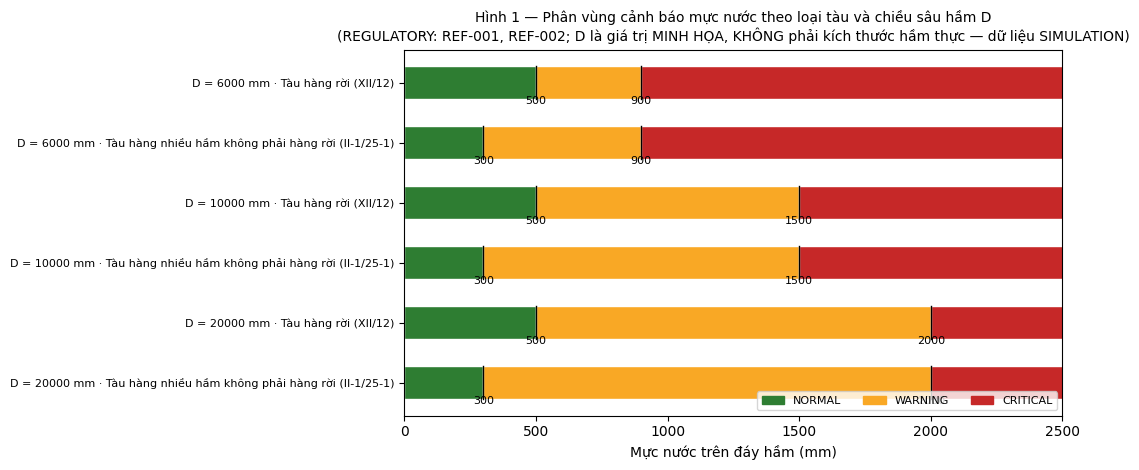

In [14]:
def zone_bar(ax, y, edges, labels=None, height=0.55):
    '''Vẽ thanh phân vùng NORMAL/WARNING/CRITICAL từ các biên [x0, x_warn, x_crit, x_end].'''
    x0, xw, xc, x1 = edges
    for (a, b, s) in [(x0, xw, NORMAL), (xw, xc, WARNING), (xc, x1, CRITICAL)]:
        ax.barh(y, b - a, left=a, height=height, color=STATE_COLORS[s], edgecolor="white", linewidth=1)
    for x in (xw, xc):
        ax.plot([x, x], [y - height / 2, y + height / 2], color="black", lw=1)

# ---- Hình 1: phân vùng cảnh báo mực nước ----
fig, ax = plt.subplots(figsize=(11, 4.8))
ys, ylabels = [], []
y = 0
for D in (6000.0, 10000.0, 20000.0):
    for vt, nice in (("bulk_carrier", "Tàu hàng rời (XII/12)"), ("multi_hold_cargo_non_bulk", "Tàu hàng nhiều hầm không phải hàng rời (II-1/25-1)")):
        warn = VESSEL_PROFILES[vt]["water_warning_mm"]
        crit = calculate_water_critical_threshold(D, vt)
        zone_bar(ax, y, (0, warn, crit, 2500))
        ax.text(warn, y + 0.36, f"{warn:g}", ha="center", fontsize=8)
        ax.text(crit, y + 0.36, f"{crit:g}", ha="center", fontsize=8)
        ylabels.append(f"D = {D:g} mm · {nice}")
        ys.append(y); y += 1
ax.set_yticks(ys); ax.set_yticklabels(ylabels, fontsize=8); ax.invert_yaxis()
ax.set_xlim(0, 2500); ax.set_xlabel("Mực nước trên đáy hầm (mm)")
ax.set_title("Hình 1 — Phân vùng cảnh báo mực nước theo loại tàu và chiều sâu hầm D\n(REGULATORY: REF-001, REF-002; D là giá trị MINH HỌA, KHÔNG phải kích thước hầm thực — dữ liệu SIMULATION)", fontsize=10)
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in (NORMAL, WARNING, CRITICAL)]
ax.legend(handles, [NORMAL, WARNING, CRITICAL], loc="lower right", ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

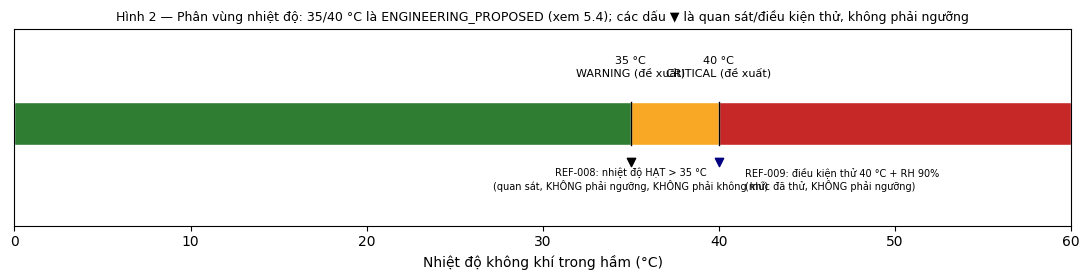

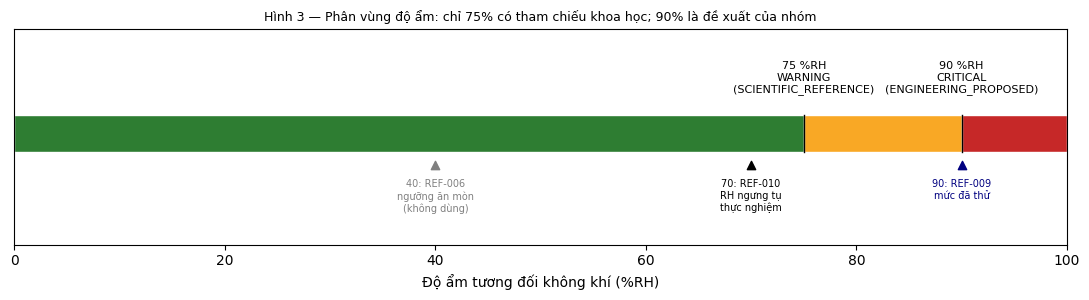

In [15]:
# ---- Hình 2: phân vùng nhiệt độ không khí ----
fig, ax = plt.subplots(figsize=(11, 2.9))
zone_bar(ax, 0, (0, 35, 40, 60), height=0.5)
for x, lab in ((35, "35 °C\nWARNING (đề xuất)"), (40, "40 °C\nCRITICAL (đề xuất)")):
    ax.text(x, 0.55, lab, ha="center", fontsize=8)
ax.scatter([35], [-0.45], marker="v", color="black", zorder=5); ax.text(35, -0.78, "REF-008: nhiệt độ HẠT > 35 °C\n(quan sát, KHÔNG phải ngưỡng, KHÔNG phải không khí)", ha="center", fontsize=7)
ax.scatter([40], [-0.45], marker="v", color="navy", zorder=5); ax.text(41.5, -0.78, "REF-009: điều kiện thử 40 °C + RH 90%\n(mức đã thử, KHÔNG phải ngưỡng)", ha="left", fontsize=7)
ax.set_xlim(0, 60); ax.set_ylim(-1.2, 1.1); ax.set_yticks([]); ax.set_xlabel("Nhiệt độ không khí trong hầm (°C)")
ax.set_title("Hình 2 — Phân vùng nhiệt độ: 35/40 °C là ENGINEERING_PROPOSED (xem 5.4); các dấu ▼ là quan sát/điều kiện thử, không phải ngưỡng", fontsize=9)
plt.tight_layout(); plt.show()

# ---- Hình 3: phân vùng độ ẩm ----
fig, ax = plt.subplots(figsize=(11, 3.1))
zone_bar(ax, 0, (0, 75, 90, 100), height=0.5)
ax.text(75, 0.55, "75 %RH\nWARNING\n(SCIENTIFIC_REFERENCE)", ha="center", fontsize=8)
ax.text(90, 0.55, "90 %RH\nCRITICAL\n(ENGINEERING_PROPOSED)", ha="center", fontsize=8)
for x, lab, col in ((70, "70: REF-010\nRH ngưng tụ\nthực nghiệm", "black"), (40, "40: REF-006\nngưỡng ăn mòn\n(không dùng)", "gray"), (90, "90: REF-009\nmức đã thử", "navy")):
    ax.scatter([x], [-0.42], marker="^", color=col, zorder=5); ax.text(x, -0.62, lab, ha="center", va="top", fontsize=7, color=col)
ax.set_xlim(0, 100); ax.set_ylim(-1.5, 1.4); ax.set_yticks([]); ax.set_xlabel("Độ ẩm tương đối không khí (%RH)")
ax.set_title("Hình 3 — Phân vùng độ ẩm: chỉ 75% có tham chiếu khoa học; 90% là đề xuất của nhóm", fontsize=9)
plt.tight_layout(); plt.show()

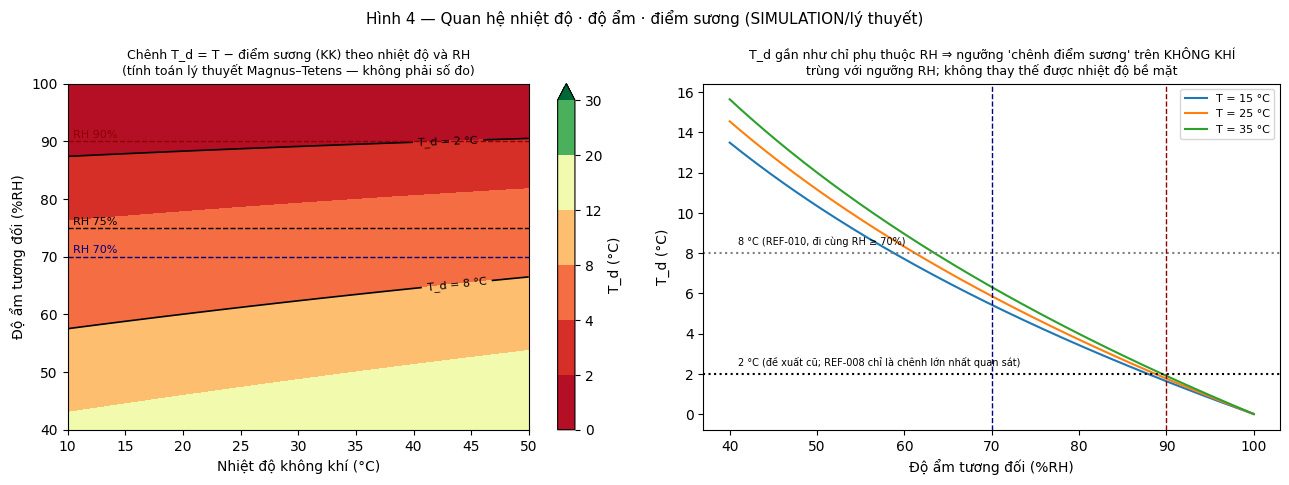

RH_%,70,75,90
T_°C,,,
15,5.43,4.40,1.63
25,5.86,4.75,1.76
35,6.31,5.11,1.90


In [16]:
# ---- Hình 4: quan hệ nhiệt độ – độ ẩm – điểm sương (tính toán lý thuyết) ----
T = np.linspace(10, 50, 161)
RH = np.linspace(40, 100, 241)
TT, RR = np.meshgrid(T, RH)
G = np.log(RR / 100.0) + 17.27 * TT / (237.7 + TT)
DP = 237.7 * G / (17.27 - G)
MARGIN = TT - DP                                     # T_d = nhiệt độ KK − điểm sương KK

fig, axes = plt.subplots(1, 2, figsize=(13, 4.9))
cs = axes[0].contourf(TT, RR, MARGIN, levels=[0, 2, 4, 8, 12, 20, 30], cmap="RdYlGn", extend="max")
c2 = axes[0].contour(TT, RR, MARGIN, levels=[2, 8], colors="black", linewidths=1.2)
axes[0].clabel(c2, fmt={2: "T_d = 2 °C", 8: "T_d = 8 °C"}, fontsize=8)
for rh, col in ((70, "navy"), (75, "black"), (90, "darkred")):
    axes[0].axhline(rh, color=col, ls="--", lw=1); axes[0].text(10.5, rh + 0.6, f"RH {rh}%", fontsize=8, color=col)
axes[0].set_xlabel("Nhiệt độ không khí (°C)"); axes[0].set_ylabel("Độ ẩm tương đối (%RH)")
axes[0].set_title("Chênh T_d = T − điểm sương (KK) theo nhiệt độ và RH\n(tính toán lý thuyết Magnus–Tetens — không phải số đo)", fontsize=9)
plt.colorbar(cs, ax=axes[0], label="T_d (°C)")
for t in (15, 25, 35):
    axes[1].plot(RH, t - (237.7 * (np.log(RH / 100) + 17.27 * t / (237.7 + t)) / (17.27 - (np.log(RH / 100) + 17.27 * t / (237.7 + t)))), label=f"T = {t} °C")
axes[1].axhline(2, color="black", ls=":"); axes[1].axhline(8, color="gray", ls=":")
axes[1].text(41, 2.4, "2 °C (đề xuất cũ; REF-008 chỉ là chênh lớn nhất quan sát)", fontsize=7)
axes[1].text(41, 8.4, "8 °C (REF-010, đi cùng RH ≥ 70%)", fontsize=7)
axes[1].axvline(70, color="navy", ls="--", lw=1); axes[1].axvline(90, color="darkred", ls="--", lw=1)
axes[1].set_xlabel("Độ ẩm tương đối (%RH)"); axes[1].set_ylabel("T_d (°C)"); axes[1].legend(fontsize=8)
axes[1].set_title("T_d gần như chỉ phụ thuộc RH ⇒ ngưỡng 'chênh điểm sương' trên KHÔNG KHÍ\ntrùng với ngưỡng RH; không thay thế được nhiệt độ bề mặt", fontsize=9)
fig.suptitle("Hình 4 — Quan hệ nhiệt độ · độ ẩm · điểm sương (SIMULATION/lý thuyết)", fontsize=11)
plt.tight_layout(); plt.show()
# Kiểm chứng số: chênh T_d tại RH 90% và 75% ở 3 mức nhiệt độ
chk = pd.DataFrame([(t, rh, round(t - calculate_dew_point(t, rh), 2)) for t in (15, 25, 35) for rh in (70, 75, 90)], columns=["T_°C", "RH_%", "T_d_°C"])
display(chk.pivot(index="T_°C", columns="RH_%", values="T_d_°C"))

In [17]:
# ======================= Dữ liệu GIẢ LẬP + bộ lọc chống báo giả (dùng cho Hình 5 và mục 5.8) =======================
def simulate_rh(n=240, dt_s=5.0, seed=7):
    '''SIMULATION: độ ẩm dao động quanh 75 %RH (nền 74 + chu kỳ 20 phút + nhiễu), mô phỏng đọc mỗi 5 s. KHÔNG phải số đo thực.'''
    rng = np.random.default_rng(seed)
    t = np.arange(n) * dt_s
    return t, 74.0 + 2.0 * np.sin(2 * np.pi * t / 600.0) + rng.normal(0.0, 1.3, n)

def state_series(values, warn=75.0, crit=90.0):
    return np.array([CRITICAL if v >= crit else WARNING if v >= warn else NORMAL for v in values])

def moving_average(x, k):
    out = np.full_like(x, np.nan, dtype=float)
    for i in range(len(x)):
        out[i] = np.mean(x[max(0, i - k + 1): i + 1])
    return out

def debounce(states, n_open=3, n_close=3):
    '''Chỉ đổi sang WARNING/CRITICAL sau n_open mẫu liên tiếp ở mức đó và chỉ về NORMAL sau n_close mẫu liên tiếp.
    Đây là THAM SỐ THỬ NGHIỆM (ENGINEERING_PROPOSED), không có nguồn khoa học cho n=3.'''
    cur = NORMAL; out = []; cand = None; cnt = 0
    for s in states:
        if s == cur:
            cand, cnt = None, 0
        else:
            if s == cand:
                cnt += 1
            else:
                cand, cnt = s, 1
            need = n_close if s == NORMAL else n_open
            if cnt >= need:
                cur, cand, cnt = s, None, 0
        out.append(cur)
    return np.array(out)

def hysteresis(values, warn=75.0, band=1.0):
    '''Mở WARNING khi ≥ warn; chỉ đóng khi < warn − band. band là THAM SỐ THỬ NGHIỆM (ENGINEERING_PROPOSED).'''
    cur = NORMAL; out = []
    for v in values:
        if cur == NORMAL and v >= warn: cur = WARNING
        elif cur == WARNING and v < warn - band: cur = NORMAL
        out.append(cur)
    return np.array(out)

def transitions(states):
    return int(np.sum(states[1:] != states[:-1]))

t_sim, rh_sim = simulate_rh()
raw = state_series(rh_sim)
ma = state_series(moving_average(rh_sim, 5))
deb = debounce(raw, 3, 3)
hys = hysteresis(rh_sim, 75.0, 1.0)
cmp_df = pd.DataFrame([
    ("Thô (không lọc)", transitions(raw), "—"),
    ("Trung bình trượt N=5", transitions(ma), "N=5 mẫu = 25 s trễ trung bình (tham số thử nghiệm)"),
    ("Debounce 3 mẫu mở / 3 mẫu đóng", transitions(deb), "trễ ≥ 3 × 5 s = 15 s (tham số thử nghiệm)"),
    ("Hysteresis (đóng khi < 74 %RH)", transitions(hys), "biên 1 %RH (tham số thử nghiệm)"),
], columns=["bộ_lọc", "số_lần_đổi_trạng_thái (SIMULATION)", "độ_trễ/biên (KHÔNG có nguồn khoa học)"])
display(cmp_df)

,bộ_lọc,số_lần_đổi_trạng_thái (SIMULATION),độ_trễ/biên (KHÔNG có nguồn khoa học)
0,Thô (không lọc),62,—
1,Trung bình trượt N=5,16,N=5 mẫu = 25 s trễ trung bình (tham số thử nghiệm)
2,Debounce 3 mẫu mở / 3 mẫu đóng,6,trễ ≥ 3 × 5 s = 15 s (tham số thử nghiệm)
3,Hysteresis (đóng khi < 74 %RH),30,biên 1 %RH (tham số thử nghiệm)


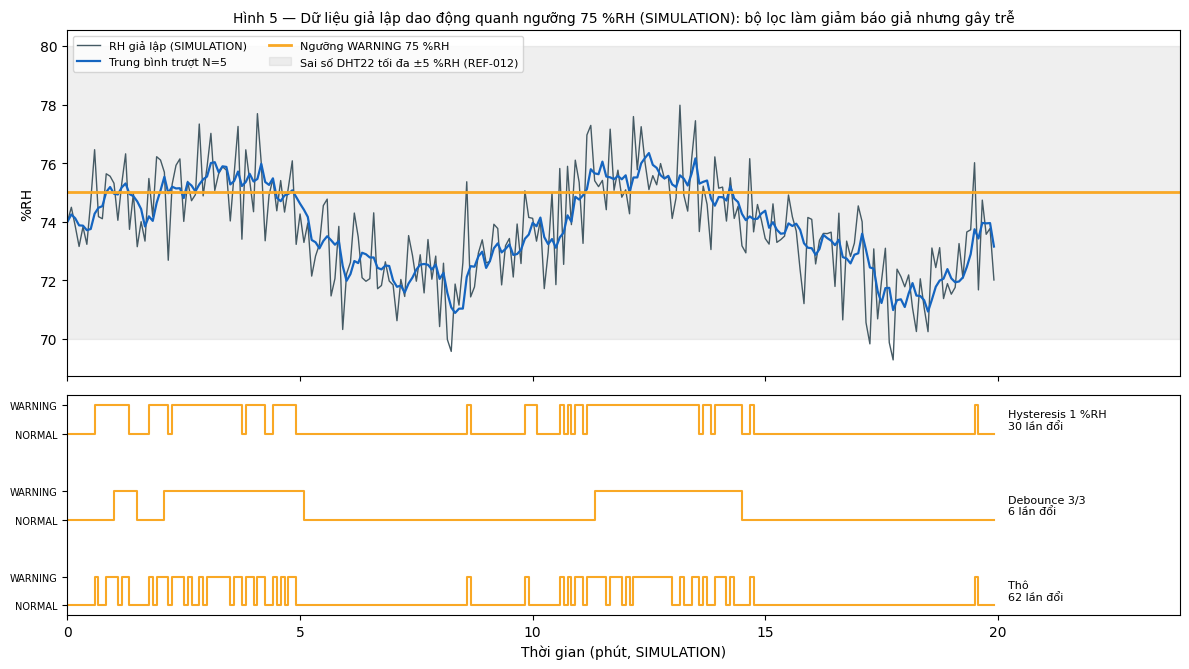

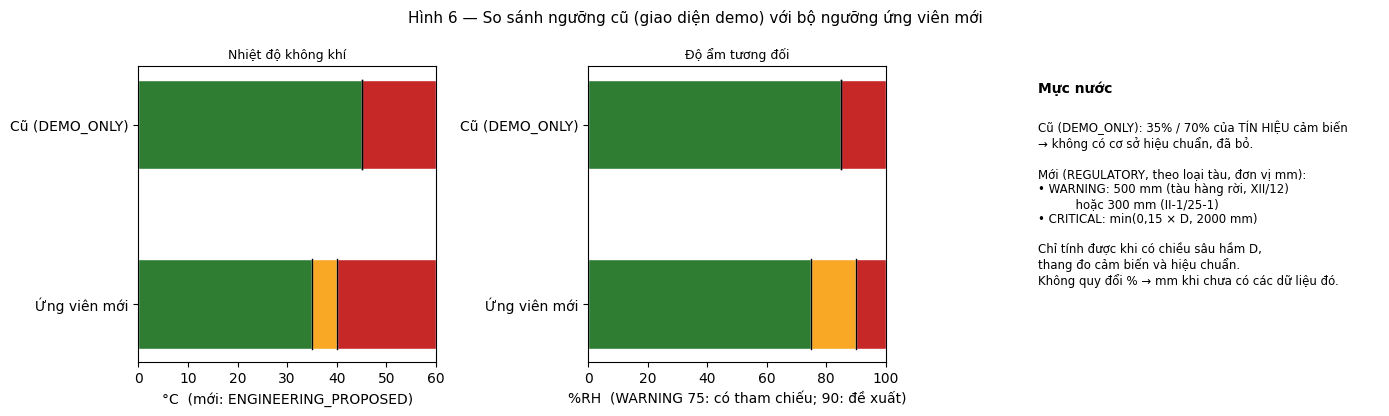

In [18]:
# ---- Hình 5: dữ liệu dao động quanh ngưỡng cảnh báo (SIMULATION) ----
fig, axes = plt.subplots(2, 1, figsize=(12, 6.8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.4]})
ax = axes[0]
ax.plot(t_sim / 60, rh_sim, color="#455a64", lw=1, label="RH giả lập (SIMULATION)")
ax.plot(t_sim / 60, moving_average(rh_sim, 5), color="#1565c0", lw=1.6, label="Trung bình trượt N=5")
ax.axhline(75, color=STATE_COLORS[WARNING], lw=2, label="Ngưỡng WARNING 75 %RH")
ax.axhspan(75 - 5, 75 + 5, color="gray", alpha=0.12, label="Sai số DHT22 tối đa ±5 %RH (REF-012)")
ax.set_ylabel("%RH"); ax.legend(loc="upper left", fontsize=8, ncol=2)
ax.set_title("Hình 5 — Dữ liệu giả lập dao động quanh ngưỡng 75 %RH (SIMULATION): bộ lọc làm giảm báo giả nhưng gây trễ", fontsize=10)
ax = axes[1]
for i, (name, s) in enumerate([("Thô", raw), ("Debounce 3/3", deb), ("Hysteresis 1 %RH", hys)]):
    y = np.where(s == WARNING, 1, np.where(s == CRITICAL, 2, 0))
    ax.step(t_sim / 60, y + i * 3, where="post", color=STATE_COLORS[WARNING] if True else "k")
    ax.text(t_sim[-1] / 60 + 0.3, i * 3 + 0.5, f"{name}\n{transitions(s)} lần đổi", fontsize=8, va="center")
ax.set_yticks([0, 1, 3, 4, 6, 7]); ax.set_yticklabels(["NORMAL", "WARNING", "NORMAL", "WARNING", "NORMAL", "WARNING"], fontsize=7)
ax.set_xlabel("Thời gian (phút, SIMULATION)"); ax.set_xlim(0, t_sim[-1] / 60 + 4)
plt.tight_layout(); plt.show()

# ---- Hình 6: so sánh ngưỡng cũ với bộ ứng viên mới ----
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.15]})
def pair_bars(ax, title, old, new, xmax, unit):
    for y, (lab, edges) in enumerate((("Cũ (UI demo)", old), ("Ứng viên mới", new))):
        zone_bar(ax, y, edges, height=0.5)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Cũ (DEMO_ONLY)", "Ứng viên mới"]); ax.invert_yaxis()
    ax.set_xlim(0, xmax); ax.set_xlabel(unit); ax.set_title(title, fontsize=9)
pair_bars(axes[0], "Nhiệt độ không khí", (0, 45, 45.001, 60), (0, 35, 40, 60), 60, "°C  (mới: ENGINEERING_PROPOSED)")
pair_bars(axes[1], "Độ ẩm tương đối", (0, 85, 85.001, 100), (0, 75, 90, 100), 100, "%RH  (WARNING 75: có tham chiếu; 90: đề xuất)")
axes[2].axis("off")
axes[2].text(0, 0.95, "Mực nước", fontsize=10, weight="bold", va="top")
axes[2].text(0, 0.82, "Cũ (DEMO_ONLY): 35% / 70% của TÍN HIỆU cảm biến\n→ không có cơ sở hiệu chuẩn, đã bỏ.\n\n"
                      "Mới (REGULATORY, theo loại tàu, đơn vị mm):\n• WARNING: 500 mm (tàu hàng rời, XII/12)\n          hoặc 300 mm (II-1/25-1)\n"
                      "• CRITICAL: min(0,15 × D, 2000 mm)\n\nChỉ tính được khi có chiều sâu hầm D,\nthang đo cảm biến và hiệu chuẩn.\n"
                      "Không quy đổi % → mm khi chưa có các dữ liệu đó.", fontsize=8.5, va="top")
fig.suptitle("Hình 6 — So sánh ngưỡng cũ (giao diện demo) với bộ ngưỡng ứng viên mới", fontsize=11)
plt.tight_layout(); plt.show()

## 5.8. Cơ chế chống cảnh báo sai

Cảnh báo sai (false alarm) làm người trực mất tin vào hệ thống; bỏ sót cảnh báo thật nguy hiểm hơn. Các kỹ thuật dưới đây giảm cảnh báo sai nhưng đều **thêm độ trễ hoặc che giá trị**, nên phải cân nhắc.

| Kỹ thuật | Tác dụng | Rủi ro / ghi chú |
|---|---|---|
| **Hysteresis** (biên trễ) | Ngăn nhấp nháy khi giá trị dao động sát ngưỡng: mở ở ≥ ngưỡng, chỉ đóng khi < ngưỡng − biên | Kéo dài cảnh báo; với nước, MSC.188(79)/Rev.2 3.3.3.1 yêu cầu chỉ báo thị giác giữ đến khi tình trạng *trở về dưới mức của đầu báo* và *không thể bị người vận hành tắt* |
| **Debounce / persistence time** | Chỉ mở cảnh báo khi vượt ngưỡng ≥ N mẫu liên tiếp | Làm chậm cảnh báo thật. MSC.188(79) 3.3.4 *cho phép* trễ để tránh báo giả do sóng sánh nhưng **không nêu số giây** |
| **Trung bình trượt** | Giảm nhiễu đo | Làm trơn đỉnh, có thể che đỉnh ngắn nguy hiểm; thêm trễ ≈ N/2 chu kỳ |
| **Nhiễu cảm biến** | DHT22: ±0,5 °C, ±2 (tối đa ±5) %RH; máy dò nước: ±100 mm | Vùng sai số quanh ngưỡng → kết quả có cờ `ambiguous` (mục 5.6) |
| **Hiệu chuẩn** | Đưa số đo về thang vật lý (mm, °C, %RH) | Nước: bắt buộc trước khi áp ngưỡng mm; DHT22: nên đối chiếu với thiết bị chuẩn |
| **Leo thang (escalation)** | Cảnh báo chưa được ACK sau T giây → tăng mức/thông báo ngoài | T là tham số vận hành; backend hiện đã có cơ chế cho cảnh báo dao động, chưa cho hầm hàng |
| **Phát hiện cảm biến offline** | Mất dữ liệu ⇒ UNKNOWN/cảnh báo lỗi, không bao giờ NORMAL | Có cơ sở quy định: MSC.188(79)/Rev.2 3.3.6 yêu cầu báo động khi hệ thống phát hiện lỗi |

**Phân loại các tham số.** Trong notebook, *mọi giá trị trễ/biên* (N=5, 3 mẫu, biên 1 %RH) là **tham số kỹ thuật thử nghiệm (ENGINEERING_PROPOSED)** — **không có nguồn khoa học**.
Duy nhất có nguồn: *được phép trễ để chống sóng sánh* (REF-005 3.3.4) và *độ chính xác ±100 mm* (REF-005 3.2.4).

**Ràng buộc an toàn.** Không áp dụng bộ lọc làm *trì hoãn cảnh báo nguy hiểm* trái yêu cầu của tiêu chuẩn tham chiếu. Đề xuất nguyên tắc: bộ lọc chỉ áp dụng cho **WARNING** (mở/đóng);
**CRITICAL của nước mở ngay tại mẫu đầu tiên vượt ngưỡng** và chỉ đóng theo hysteresis; thời gian trễ cho nước chỉ được đặt sau thử nghiệm trên tàu/bể thử.

In [19]:
# ---- Ảnh hưởng chuyển động roll/pitch tới phép đo nước (phân tích độ nhạy MINH HỌA) ----
# Mô hình hình học đơn giản: mặt nước tự do nằm ngang; khi tàu nghiêng góc θ, độ cao nước tại đầu báo cách điểm giao ℓ (m) theo phương nghiêng thay đổi Δh ≈ ℓ·tan θ.
# ℓ là THAM SỐ MINH HỌA (không phải kích thước hầm thực). Bảng chỉ để so sánh bậc độ lớn với ±100 mm và các ngưỡng 300/500 mm.
theta = np.array([0.5, 1, 2, 5, 10])
ell = np.array([2.0, 5.0, 10.0])
dh = pd.DataFrame(np.round(1000 * np.outer(np.tan(np.radians(theta)), ell), 0).astype(int), index=[f"θ = {t:g}°" for t in theta], columns=[f"ℓ = {l:g} m" for l in ell])
dh.index.name = "góc nghiêng (ILLUSTRATIVE)"
display(dh.style.map(lambda v: "background-color: #ffcdd2" if v > 100 else ""))
display(Markdown(r'''
**Nhận định (ILLUSTRATIVE — không phải số liệu tàu thật).** Với ℓ = 5 m, nghiêng 2° đã làm đầu báo đọc lệch ≈ 175 mm, *lớn hơn sai số quy định ±100 mm* và cùng bậc với ngưỡng 300–500 mm.
Do đó khi tàu lắc, đọc mực nước tức thời có thể nhảy vượt ngưỡng dù lượng nước không đổi (sóng sánh), và ngược lại. Hệ quả:

* đây là lý do MSC.188(79) 3.3.4 cho phép trễ thời gian, và là lý do đầu báo phải ở *phía đuôi hầm, tại chỗ trũng nhất* (3.1.2);
* hệ thống có dữ liệu Roll/Pitch của Motion Node, nên **có thể** dùng để *gắn nhãn độ tin cậy* cho mẫu nước khi |roll|/|pitch| lớn (chỉ là đề xuất nghiên cứu; **không** sửa logic Roll/Pitch/MAI/ML hiện có);
* mọi quyết định về thời gian trễ hoặc bù nghiêng phải dựa trên thử nghiệm bể/tàu — **chưa có dữ liệu thực nghiệm** trong repo.
'''))

,ℓ = 2 m,ℓ = 5 m,ℓ = 10 m
góc nghiêng (ILLUSTRATIVE),,,
θ = 0.5°,17,44,87
θ = 1°,35,87,175
θ = 2°,70,175,349
θ = 5°,175,437,875
θ = 10°,353,882,1763



**Nhận định (ILLUSTRATIVE — không phải số liệu tàu thật).** Với ℓ = 5 m, nghiêng 2° đã làm đầu báo đọc lệch ≈ 175 mm, *lớn hơn sai số quy định ±100 mm* và cùng bậc với ngưỡng 300–500 mm.
Do đó khi tàu lắc, đọc mực nước tức thời có thể nhảy vượt ngưỡng dù lượng nước không đổi (sóng sánh), và ngược lại. Hệ quả:

* đây là lý do MSC.188(79) 3.3.4 cho phép trễ thời gian, và là lý do đầu báo phải ở *phía đuôi hầm, tại chỗ trũng nhất* (3.1.2);
* hệ thống có dữ liệu Roll/Pitch của Motion Node, nên **có thể** dùng để *gắn nhãn độ tin cậy* cho mẫu nước khi |roll|/|pitch| lớn (chỉ là đề xuất nghiên cứu; **không** sửa logic Roll/Pitch/MAI/ML hiện có);
* mọi quyết định về thời gian trễ hoặc bù nghiêng phải dựa trên thử nghiệm bể/tàu — **chưa có dữ liệu thực nghiệm** trong repo.


## 5.9. Ma trận truy xuất nguồn gốc

Luồng: **Nguồn khoa học → Bằng chứng/điều khoản → Ngưỡng → Cảm biến & đại lượng → Firmware ESP32 → MQTT/Data contract → Backend → Web/Mobile → Test case.**
Các cột `check_*` được **kiểm tra tự động trên repo khi chạy notebook** (tìm đúng từ khóa trong tệp tương ứng); `gap` ghi những mắt xích còn thiếu.

In [20]:
def contains(rel: str, *needles: str) -> bool:
    txt = read(rel)
    return bool(txt) and all(n in txt for n in needles)

def test_exists(*names: str) -> bool:
    txt = read("tests/backend/test_cargo_alerts.py")
    return bool(txt) and all(re.search(rf"def {re.escape(n)}\b", txt) for n in names)

TRACE = pd.DataFrame([
 dict(threshold_id="T-01", level="Nước WARNING 500 mm (tàu hàng rời)", evidence="REF-001 · SOLAS XII/12.1.1", threshold_type="REGULATORY",
      sensor_variable="mực nước (mm) ← % tín hiệu chiết áp (CHƯA hiệu chuẩn)", firmware="firmware/target_cargo/src/main.cpp::read_water_pct (chỉ % tín hiệu)",
      mqtt_contract="contracts/schemas/cargo.json: cargo_water_pct (%)", backend="backend/cargo/thresholds.py DEFAULTS water.warning_mm=500 (một giá trị cho MỌI loại tàu)",
      web_mobile="frontend LivePages CargoStatus (hiển thị trạng thái backend); mobile: chưa hiển thị", test="test_water_boundaries_depth_10000",
      check_firmware=contains("firmware/target_cargo/src/main.cpp", "read_water_pct"), check_contract=contains("contracts/schemas/cargo.json", "cargo_water_pct"),
      check_backend=contains("backend/cargo/thresholds.py", "warning_mm"), check_frontend=contains("frontend/src/live/LivePages.tsx", "CargoStatus"),
      check_test=test_exists("test_water_boundaries_depth_10000"),
      gap="Backend chưa phân biệt vessel_type (II-1/25-1: 300 mm); firmware chỉ gửi %, thiếu mm"),
 dict(threshold_id="T-02", level="Nước CRITICAL min(0,15·D, 2000 mm)", evidence="REF-001/REF-002 · XII/12.1.1; II-1/25-1.2.1", threshold_type="REGULATORY (diễn giải)",
      sensor_variable="mực nước (mm) + chiều sâu hầm D", firmware="— (không có D trong firmware)", mqtt_contract="— (D nằm ở cấu hình backend: cargo_hold_depth_mm)",
      backend="backend/cargo/thresholds.py water_critical_mm(); bảng cargo_hold_configs", web_mobile="frontend: hiển thị NOT_CONFIGURED khi thiếu D", test="test_water_critical_is_capped_at_2000mm_for_deep_holds",
      check_firmware=False, check_contract=False, check_backend=contains("backend/cargo/thresholds.py", "def water_critical_mm"),
      check_frontend=contains("frontend/src/live/LivePages.tsx", "missing_config"), check_test=test_exists("test_water_critical_is_capped_at_2000mm_for_deep_holds"),
      gap="D và thang đo cảm biến CHƯA có giá trị; diễn giải khi D > 13,33 m chưa thống nhất"),
 dict(threshold_id="T-03", level="Nước WARNING 300 mm (tàu hàng nhiều hầm không phải hàng rời — thường gồm tàu container)", evidence="REF-002 · SOLAS II-1/25-1.2.1", threshold_type="REGULATORY",
      sensor_variable="mực nước (mm)", firmware="như T-01", mqtt_contract="như T-01", backend="CHƯA CÓ (backend chỉ có 500 mm)", web_mobile="—", test="— (chưa có test)",
      check_firmware=False, check_contract=False, check_backend=False, check_frontend=False, check_test=False,
      gap="Ngưỡng bổ sung theo đối tượng đề cương (tàu container) — cần nhóm quyết định rồi mới triển khai"),
 dict(threshold_id="T-04", level="Nhiệt độ WARNING 35 °C", evidence="Nhóm đề xuất; REF-008 chỉ là bối cảnh (nhiệt độ hạt)", threshold_type="ENGINEERING_PROPOSED",
      sensor_variable="nhiệt độ KHÔNG KHÍ (DHT22)", firmware="firmware/target_cargo/src/main.cpp::read_dht", mqtt_contract="contracts/schemas/cargo.json: cargo_temp_c",
      backend="backend/cargo/thresholds.py DEFAULTS temperature.warning=35", web_mobile="frontend CargoStatus; mobile: chưa", test="test_temperature_boundaries",
      check_firmware=contains("firmware/target_cargo/src/main.cpp", "readTemperature"), check_contract=contains("contracts/schemas/cargo.json", "cargo_temp_c"),
      check_backend=contains("backend/cargo/thresholds.py", '"temperature"'), check_frontend=contains("frontend/src/live/LivePages.tsx", "TEMPERATURE"), check_test=test_exists("test_temperature_boundaries"),
      gap="Backend ghi tham chiếu Wang & Zhou cho ngưỡng này nhưng bài báo KHÔNG nêu ngưỡng → cần sửa chú thích"),
 dict(threshold_id="T-05", level="Nhiệt độ CRITICAL 40 °C", evidence="Nhóm đề xuất; REF-009 chỉ là điều kiện thử", threshold_type="ENGINEERING_PROPOSED",
      sensor_variable="nhiệt độ KHÔNG KHÍ (DHT22)", firmware="như T-04", mqtt_contract="như T-04", backend="DEFAULTS temperature.critical=40", web_mobile="như T-04", test="test_temperature_boundaries",
      check_firmware=contains("firmware/target_cargo/src/main.cpp", "readTemperature"), check_contract=contains("contracts/schemas/cargo.json", "cargo_temp_c"),
      check_backend=contains("backend/cargo/thresholds.py", '"critical": 40.0'), check_frontend=contains("frontend/src/live/LivePages.tsx", "TEMPERATURE"), check_test=test_exists("test_temperature_boundaries"),
      gap="Như T-04"),
 dict(threshold_id="T-06", level="Độ ẩm WARNING 75 %RH", evidence="REF-006 (CTU Code, mould growth threshold); REF-010 (RH ≥ 70%)", threshold_type="SCIENTIFIC_REFERENCE",
      sensor_variable="RH KHÔNG KHÍ (DHT22)", firmware="firmware/target_cargo/src/main.cpp::read_dht", mqtt_contract="contracts/schemas/cargo.json: cargo_humidity_pct",
      backend="DEFAULTS humidity.warning=75", web_mobile="frontend CargoStatus; mobile: chưa", test="test_humidity_boundaries",
      check_firmware=contains("firmware/target_cargo/src/main.cpp", "readHumidity"), check_contract=contains("contracts/schemas/cargo.json", "cargo_humidity_pct"),
      check_backend=contains("backend/cargo/thresholds.py", '"humidity"'), check_frontend=contains("frontend/src/live/LivePages.tsx", "HUMIDITY"), check_test=test_exists("test_humidity_boundaries"),
      gap="Số điều khoản CTU Code chưa xác định; sai số DHT22 ±2…5 %RH"),
 dict(threshold_id="T-07", level="Độ ẩm CRITICAL 90 %RH", evidence="Nhóm đề xuất; REF-009 chỉ là mức đã thử", threshold_type="ENGINEERING_PROPOSED",
      sensor_variable="RH KHÔNG KHÍ (DHT22)", firmware="như T-06", mqtt_contract="như T-06", backend="DEFAULTS humidity.critical=90", web_mobile="như T-06", test="test_humidity_boundaries",
      check_firmware=contains("firmware/target_cargo/src/main.cpp", "readHumidity"), check_contract=contains("contracts/schemas/cargo.json", "cargo_humidity_pct"),
      check_backend=contains("backend/cargo/thresholds.py", '"critical": 90.0'), check_frontend=contains("frontend/src/live/LivePages.tsx", "HUMIDITY"), check_test=test_exists("test_humidity_boundaries"),
      gap="Không nguồn nào nêu 90% là ngưỡng cảnh báo"),
 dict(threshold_id="T-08", level="Chênh lệch điểm sương >2 / 0–2 / ≤0 °C", evidence="KHÔNG CÓ (REF-008 chỉ quan sát 2 °C; REF-010 đề xuất T_d ≤ 8 °C & RH ≥ 70%)", threshold_type="ENGINEERING_PROPOSED → NOT_SUPPORTED",
      sensor_variable="nhiệt độ − điểm sương (KK, từ DHT22)", firmware="— (firmware không tính điểm sương)", mqtt_contract="—", backend="KHÔNG triển khai", web_mobile="—", test="—",
      check_firmware=False, check_contract=False, check_backend=False, check_frontend=False, check_test=False,
      gap="Không nên triển khai bộ ngưỡng này; xem phương án A-01 (REF-010) nếu cần cảnh báo ngưng tụ"),
])
check_cols = [c for c in TRACE.columns if c.startswith("check_")]
display(TRACE[["threshold_id", "level", "evidence", "threshold_type", "sensor_variable"]])
display(TRACE[["threshold_id", "firmware", "mqtt_contract", "backend", "web_mobile", "test", "gap"]])
display(TRACE[["threshold_id"] + check_cols].set_index("threshold_id").map(lambda b: "✔" if b else "✘"))

,threshold_id,level,evidence,threshold_type,sensor_variable
0,T-01,Nước WARNING 500 mm (tàu hàng rời),REF-001 · SOLAS XII/12.1.1,REGULATORY,mực nước (mm) ← % tín hiệu chiết áp (CHƯA hiệu chuẩn)
1,T-02,"Nước CRITICAL min(0,15·D, 2000 mm)",REF-001/REF-002 · XII/12.1.1; II-1/25-1.2.1,REGULATORY (diễn giải),mực nước (mm) + chiều sâu hầm D
2,T-03,Nước WARNING 300 mm (tàu hàng nhiều hầm không phải hàng rời — thường gồm tàu container),REF-002 · SOLAS II-1/25-1.2.1,REGULATORY,mực nước (mm)
3,T-04,Nhiệt độ WARNING 35 °C,Nhóm đề xuất; REF-008 chỉ là bối cảnh (nhiệt độ hạt),ENGINEERING_PROPOSED,nhiệt độ KHÔNG KHÍ (DHT22)
4,T-05,Nhiệt độ CRITICAL 40 °C,Nhóm đề xuất; REF-009 chỉ là điều kiện thử,ENGINEERING_PROPOSED,nhiệt độ KHÔNG KHÍ (DHT22)
5,T-06,Độ ẩm WARNING 75 %RH,"REF-006 (CTU Code, mould growth threshold); REF-010 (RH ≥ 70%)",SCIENTIFIC_REFERENCE,RH KHÔNG KHÍ (DHT22)
6,T-07,Độ ẩm CRITICAL 90 %RH,Nhóm đề xuất; REF-009 chỉ là mức đã thử,ENGINEERING_PROPOSED,RH KHÔNG KHÍ (DHT22)
7,T-08,Chênh lệch điểm sương >2 / 0–2 / ≤0 °C,KHÔNG CÓ (REF-008 chỉ quan sát 2 °C; REF-010 đề xuất T_d ≤ 8 °C & RH ≥ 70%),ENGINEERING_PROPOSED → NOT_SUPPORTED,"nhiệt độ − điểm sương (KK, từ DHT22)"


,threshold_id,firmware,mqtt_contract,backend,web_mobile,test,gap
0,T-01,firmware/target_cargo/src/main.cpp::read_water_pct (chỉ % tín hiệu),contracts/schemas/cargo.json: cargo_water_pct (%),backend/cargo/thresholds.py DEFAULTS water.warning_mm=500 (một giá trị cho MỌI loại tàu),frontend LivePages CargoStatus (hiển thị trạng thái backend); mobile: chưa hiển thị,test_water_boundaries_depth_10000,"Backend chưa phân biệt vessel_type (II-1/25-1: 300 mm); firmware chỉ gửi %, thiếu mm"
1,T-02,— (không có D trong firmware),— (D nằm ở cấu hình backend: cargo_hold_depth_mm),backend/cargo/thresholds.py water_critical_mm(); bảng cargo_hold_configs,frontend: hiển thị NOT_CONFIGURED khi thiếu D,test_water_critical_is_capped_at_2000mm_for_deep_holds,"D và thang đo cảm biến CHƯA có giá trị; diễn giải khi D > 13,33 m chưa thống nhất"
2,T-03,như T-01,như T-01,CHƯA CÓ (backend chỉ có 500 mm),—,— (chưa có test),Ngưỡng bổ sung theo đối tượng đề cương (tàu container) — cần nhóm quyết định rồi mới triển khai
3,T-04,firmware/target_cargo/src/main.cpp::read_dht,contracts/schemas/cargo.json: cargo_temp_c,backend/cargo/thresholds.py DEFAULTS temperature.warning=35,frontend CargoStatus; mobile: chưa,test_temperature_boundaries,Backend ghi tham chiếu Wang & Zhou cho ngưỡng này nhưng bài báo KHÔNG nêu ngưỡng → cần sửa chú thích
4,T-05,như T-04,như T-04,DEFAULTS temperature.critical=40,như T-04,test_temperature_boundaries,Như T-04
5,T-06,firmware/target_cargo/src/main.cpp::read_dht,contracts/schemas/cargo.json: cargo_humidity_pct,DEFAULTS humidity.warning=75,frontend CargoStatus; mobile: chưa,test_humidity_boundaries,Số điều khoản CTU Code chưa xác định; sai số DHT22 ±2…5 %RH
6,T-07,như T-06,như T-06,DEFAULTS humidity.critical=90,như T-06,test_humidity_boundaries,Không nguồn nào nêu 90% là ngưỡng cảnh báo
7,T-08,— (firmware không tính điểm sương),—,KHÔNG triển khai,—,—,Không nên triển khai bộ ngưỡng này; xem phương án A-01 (REF-010) nếu cần cảnh báo ngưng tụ


,check_firmware,check_contract,check_backend,check_frontend,check_test
threshold_id,,,,,
T-01,✔,✔,✔,✔,✔
T-02,✘,✘,✔,✔,✔
T-03,✘,✘,✘,✘,✘
T-04,✔,✔,✔,✔,✔
T-05,✔,✔,✔,✔,✔
T-06,✔,✔,✔,✔,✔
T-07,✔,✔,✔,✔,✔
T-08,✘,✘,✘,✘,✘


In [21]:
# ---- So khớp bộ ngưỡng trong notebook với DEFAULTS của backend (phát hiện lệch) ----
thr_py = read("backend/cargo/thresholds.py")
m = re.search(r"DEFAULTS[^=]*=\s*(\{.*?\n\})", thr_py, flags=re.S)
backend_defaults = {}
if m:
    try:
        backend_defaults = ast.literal_eval(m.group(1))
    except Exception as e:
        print("Không phân tích được DEFAULTS:", e)

def bd(group, key):
    return backend_defaults.get(group, {}).get(key, "KHÔNG ĐỌC ĐƯỢC")

drift = pd.DataFrame([
    ("Nước WARNING (hàng rời)", 500.0, bd("water", "warning_mm")),
    ("Nước WARNING (hầm nhiều, non-bulk)", 300.0, "backend không có theo vessel_type"),
    ("Nước CRITICAL: hệ số × D", 0.15, bd("water", "critical_fraction_of_depth")),
    ("Nước CRITICAL: trần (mm)", 2000.0, bd("water", "critical_cap_mm")),
    ("Nhiệt độ WARNING", 35.0, bd("temperature", "warning")),
    ("Nhiệt độ CRITICAL", 40.0, bd("temperature", "critical")),
    ("Độ ẩm WARNING", 75.0, bd("humidity", "warning")),
    ("Độ ẩm CRITICAL", 90.0, bd("humidity", "critical")),
], columns=["tham_số", "notebook", "backend_DEFAULTS"])
drift["khớp"] = [("✔" if a == b else "✘") for a, b in zip(drift.notebook, drift.backend_DEFAULTS)]
display(drift)
ref_text = re.findall(r"Wang & Zhou[^\"\n]*", thr_py)
print("Backend còn ghi tham chiếu 'Wang & Zhou' cho ngưỡng nhiệt độ:", bool(ref_text),
      "→ bài báo KHÔNG nêu ngưỡng 35/40 °C; cần sửa chú thích ở bước triển khai.")

,tham_số,notebook,backend_DEFAULTS,khớp
0,Nước WARNING (hàng rời),500.00,500.0,✔
1,"Nước WARNING (hầm nhiều, non-bulk)",300.00,backend không có theo vessel_type,✘
2,Nước CRITICAL: hệ số × D,0.15,0.15,✔
3,Nước CRITICAL: trần (mm),2000.00,2000.0,✔
4,Nhiệt độ WARNING,35.00,35.0,✔
5,Nhiệt độ CRITICAL,40.00,40.0,✔
6,Độ ẩm WARNING,75.00,75.0,✔
7,Độ ẩm CRITICAL,90.00,90.0,✔


Backend còn ghi tham chiếu 'Wang & Zhou' cho ngưỡng nhiệt độ: True → bài báo KHÔNG nêu ngưỡng 35/40 °C; cần sửa chú thích ở bước triển khai.


## 5.10. Kết luận nghiên cứu

In [22]:
n_verified   = int((SOURCES.verification_status == "VERIFIED").sum())
n_partial    = int((SOURCES.verification_status == "PARTIALLY_VERIFIED").sum())
n_unverified = int((SOURCES.verification_status == "UNVERIFIED").sum())
thr = CAND[CAND.candidate_id.str.startswith("C-")]
n_direct   = int(thr.verdict.str.startswith("SUPPORTED").sum())
n_partial_s= int((thr.verdict == "PARTIALLY_SUPPORTED").sum())
n_proposed = int((thr.verdict == "PROPOSED_ONLY").sum())
n_not      = int((thr.verdict == "NOT_SUPPORTED").sum())
n_phys     = int((thr.verdict == "PHYSICAL_DEFINITION").sum())

summary = pd.DataFrame([
    ("Nguồn VERIFIED", n_verified), ("Nguồn PARTIALLY_VERIFIED", n_partial), ("Nguồn UNVERIFIED", n_unverified), ("Tổng nguồn", len(SOURCES)),
    ("Ngưỡng ứng viên có căn cứ TRỰC TIẾP (SUPPORTED_*)", n_direct),
    ("Ngưỡng có căn cứ MỘT PHẦN (PARTIALLY_SUPPORTED)", n_partial_s),
    ("Ngưỡng chỉ là ĐỀ XUẤT của nhóm (PROPOSED_ONLY)", n_proposed),
    ("Ngưỡng KHÔNG có căn cứ (NOT_SUPPORTED)", n_not),
    ("Định nghĩa vật lý (không phải ngưỡng cảnh báo)", n_phys),
    ("Test case đạt", f"{n_pass}/{n_total}"),
], columns=["chỉ_số", "giá_trị"])
display(summary)

,chỉ_số,giá_trị
0,Nguồn VERIFIED,9
1,Nguồn PARTIALLY_VERIFIED,5
2,Nguồn UNVERIFIED,1
3,Tổng nguồn,15
4,Ngưỡng ứng viên có căn cứ TRỰC TIẾP (SUPPORTED_*),3
5,Ngưỡng có căn cứ MỘT PHẦN (PARTIALLY_SUPPORTED),2
6,Ngưỡng chỉ là ĐỀ XUẤT của nhóm (PROPOSED_ONLY),3
7,Ngưỡng KHÔNG có căn cứ (NOT_SUPPORTED),2
8,Định nghĩa vật lý (không phải ngưỡng cảnh báo),1
9,Test case đạt,80/80


### Trả lời các câu hỏi nghiệm thu

**1. Ngưỡng nào được quy định trực tiếp bởi tiêu chuẩn hàng hải?**
Chỉ các ngưỡng **mực nước**, và **phụ thuộc loại tàu**: tàu hàng rời — báo động đầu **0,5 m**, báo động hai ≥ 15% chiều sâu hầm nhưng ≤ 2 m (SOLAS XII/12.1.1, `REF-001`);
tàu hàng nhiều hầm không phải hàng rời/tàu dầu đóng từ 01/01/2024 — báo động đầu **0,3 m**, báo động hai ≥ 15% chiều sâu nhưng ≤ 2 m (SOLAS II-1/25-1.2.1, `REF-002`).
Không có quy định hàng hải nào (trong các nguồn đọc được) nêu ngưỡng nhiệt độ hay độ ẩm hầm hàng.

**2. Ngưỡng nào có bằng chứng thực nghiệm?**
Không có ngưỡng nhiệt độ/độ ẩm nào được nguồn nêu *là ngưỡng cảnh báo*. Bằng chứng thực nghiệm chỉ là **điều kiện/quan sát**: ngưng tụ trong container khi **T_d ≤ 8 °C và RH ≥ 70%** (`REF-010`);
nhiệt độ hạt đậu nành > 35 °C và RH hạt sát mạn tới 95% (`REF-008`, quan sát); mốc tăng ở 40 °C và RH 90% (`REF-009`, điều kiện thử). Các giá trị này **không** được đánh đồng với ngưỡng bắt buộc.

**3. Ngưỡng nào do nhóm đề xuất?**
Nhiệt độ **35/40 °C**, độ ẩm **CRITICAL 90%**, và bộ **chênh điểm sương 2/0 °C** (bộ cuối **không có căn cứ**, nên không nên triển khai). Độ ẩm **WARNING 75%** có tham chiếu khoa học (CTU Code) nhưng không bắt buộc.

**4. Ngưỡng nào triển khai được ngay với mạch hiện tại?**
Nhiệt độ và độ ẩm (DHT22 đo trực tiếp nhiệt độ/độ ẩm *không khí*) — nhưng chỉ như **ngưỡng kỹ thuật của prototype** với nhãn rõ ràng, không phải cảnh báo an toàn. Backend hiện đã làm như vậy.

**5. Ngưỡng nào cần hiệu chuẩn cảm biến?**
**Nước (mm)**: cần hiệu chuẩn chiết áp/ADC và thang đo (`water_sensor_full_scale_mm`). Nhiệt độ/độ ẩm: nên đối chiếu DHT22 với thiết bị chuẩn trước khi dùng cho dữ liệu `SENSOR` (cờ `sensor_calibrated`).

**6. Ngưỡng nào cần bổ sung phần cứng hoặc dữ liệu?**
Nước: cần **cảm biến mực nước thật** (hiện chỉ có chiết áp mô phỏng; model chưa xác định) đạt yêu cầu thử kiểu/IP68/mạch an toàn nội tại (`REF-005`) và dữ liệu **chiều sâu hầm hàng**.
Ngưng tụ: cần **nhiệt độ bề mặt vách/trần** (DHT22 không đo). Rủi ro hàng: cần **nhiệt độ khối hàng** và độ ẩm hàng nếu muốn dùng các kết quả của `REF-008`/`REF-009`.

**7. Hệ thống còn những hạn chế nào?**
(i) Prototype, chưa chứng nhận; (ii) đối tượng đề cương là **tàu container** nhưng ngưỡng ban đầu lấy từ ngữ cảnh **tàu hàng rời, hàng nông sản**; (iii) ngưỡng nước phụ thuộc loại tàu mà backend hiện dùng một giá trị;
(iv) 35/40 °C và 90% không có nguồn; (v) DHT22 sai số ±2…5 %RH, không dùng khi đọng sương, không dùng cho thiết bị an toàn; (vi) chưa có dữ liệu thực nghiệm hay thử nghiệm trên tàu;
(vii) một số nguồn chỉ đọc một phần (CTU Code, SOLAS XII/12 qua bản tái hiện, tóm tắt `REF-011`); IMSBC chưa xác minh được; (viii) câu chữ "≥ 15% chiều sâu nhưng ≤ 2 m" mâu thuẫn khi hầm sâu hơn 13,33 m.

**8. Cần thử nghiệm gì trước khi áp dụng vào môi trường thực tế?**
Xác nhận loại tàu/nhóm quy định áp dụng với đăng kiểm; đọc diễn giải thống nhất (ví dụ MSC.1/Circ.1464, chưa đọc) về độ cao báo động; đo chiều sâu hầm và hiệu chuẩn thang đo mực nước trong bể thử;
thử kiểu cảm biến nước (IP68, hàng/nước biển); thử độ trễ chống sóng sánh trên mô hình/tàu với các góc roll/pitch thực; đối chiếu DHT22 với thiết bị chuẩn trong buồng nhiệt ẩm, kể cả vùng RH > 90%;
đo nhiệt độ vách hầm cùng nhiệt độ không khí để kiểm định điều kiện ngưng tụ; đánh giá tỉ lệ cảnh báo sai/bỏ sót trên dữ liệu thực.

### Câu hỏi mở cần nhóm quyết định (không tự quyết trong notebook)

* **Loại tàu áp dụng cho bộ ngưỡng nước**: tàu container (II-1/25-1, 300 mm) hay tàu hàng rời (XII/12, 500 mm)? Đề cương hiện hành là tàu container.
* Có đổi chú thích tham chiếu của backend cho ngưỡng nhiệt độ/độ ẩm (35/40/90) thành "ngưỡng kỹ thuật do nhóm đề xuất" không?
* Có dừng bộ "chênh điểm sương 2/0 °C" và thay bằng điều kiện thực nghiệm `T_d ≤ 8 °C & RH ≥ 70%` (REF-010) hay không?

> **Bước tiếp theo** (chỉ sau khi nhóm phê duyệt phạm vi): cập nhật cấu hình/ngưỡng trong hệ thống theo các quyết định trên. Notebook này không thay đổi mã nguồn nào.

### Phụ lục — nhật ký truy cập nguồn (2026-11-28)

| Nguồn | Kết quả truy cập |
|---|---|
| MDPI (Wang & Zhou) | Mở được toàn văn, đối chiếu metadata/DOI |
| Wiley (Song và cộng sự) | Mở được toàn văn, đối chiếu metadata/DOI |
| Cambridge (Yuen và cộng sự) | Trang nhà xuất bản có phí; **đọc bản chấp nhận đăng mở ở kho Kobe University** (cùng DOI) |
| Springer (Barreiro & Sandoval) | Toàn văn có phí; chỉ đọc tóm tắt qua NASA/ADS |
| IMO — MSC.188(79) | Mở được PDF trên `wwwcdn.imo.org` |
| IMO — MSC.188(79)/Rev.2 | Mở được PDF (bản lưu ở puc.overheid.nl) |
| SOLAS XII/12; II-1/25, 25-1 | Đọc qua `imorules.com`; Reg. 25-1 đối chiếu thêm với ấn phẩm của MCA (UK) |
| CTU Code | PDF gốc 2014 đọc tự động trả nội dung rỗng; **đọc được bản hợp nhất 2024 của UNECE** (trích đoạn tự động, thiếu số chương/trang) |
| IMSBC Code | Trang IMO lỗi HTTP 500; toàn văn có phí → `UNVERIFIED` |
| Datasheet DHT22/AM2302 | Mở được (bản lưu tại Adafruit CDN) |
| ESP-IDF ADC docs | Mở được; không có số liệu sai số |
| MSC.1/Circ.1464 (diễn giải thống nhất) | Chỉ thấy tiêu đề trong kết quả tìm kiếm; **chưa đọc** |